In [1]:
import os

# Define the directory path structure
folders = [
    'week3_project/data/raw',
    'week3_project/data/processed'
]

# Create directories
for folder in folders:
    os.makedirs(folder, exist_ok=True)
    print(f"Created directory: {folder}")


Created directory: week3_project/data/raw
Created directory: week3_project/data/processed


# A1

In [2]:
# Cell 1 — Workspace setup (RUN FIRST)
from pathlib import Path

BASE_DIR = Path("/content/week3_project")
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Compatibility aliases for notebook examples
RAW = RAW_DIR
PROCESSED = PROCESSED_DIR
BASE = BASE_DIR
OUT = PROCESSED_DIR

print("Raw folder:", RAW_DIR)
print("Processed folder:", PROCESSED_DIR)


Raw folder: /content/week3_project/data/raw
Processed folder: /content/week3_project/data/processed


# A2


In [3]:
# Cell 3 — Verify uploaded inputs (self-contained)
from pathlib import Path
RAW = Path("/content/week3_project/data/raw")
RAW_DIR = RAW
BASE_DIR = RAW.parent.parent
PROCESSED_DIR = BASE_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
BASE = BASE_DIR
OUT = PROCESSED_DIR

files = sorted(f for f in RAW.rglob("*") if f.is_file())
print("Input count:", len(files))
for f in files:
 	print(f.relative_to(RAW), "bytes:", f.stat().st_size)

assert files, "Upload at least one relevant input file before proceeding."
print("Upload verified. Select your relevant input(s) for Step A3.")


Input count: 3
academic_calendar_2026_2027.pdf bytes: 627618
academic_regulations_2026.pdf bytes: 779259
course_registration_guide_2026_2027.pdf bytes: 2055792
Upload verified. Select your relevant input(s) for Step A3.


# A3 — Inspect your selected data sources
**Cell A3.1 — Install and import the library**

In [4]:
!pip -q install pypdf

from pathlib import Path
from pypdf import PdfReader
import re

**Cell A3.2 — Define your UTM PDF files**

In [5]:
# Define the PDF sources explicitly

sources = {
    "S01": RAW_DIR / "academic_regulations_2026.pdf",
    "S02": RAW_DIR / "course_registration_guide_2026_2027.pdf",
    "S03": RAW_DIR / "academic_calendar_2026_2027.pdf"
}

# Verify that all files exist

for source_id, file_path in sources.items():
    if not file_path.is_file():
        raise FileNotFoundError(f"Missing file: {file_path}")

    print(f"{source_id}: {file_path.name} — FOUND")

print("\nAll UniGuide PDF sources are available.")

S01: academic_regulations_2026.pdf — FOUND
S02: course_registration_guide_2026_2027.pdf — FOUND
S03: academic_calendar_2026_2027.pdf — FOUND

All UniGuide PDF sources are available.


**Cell A3.3 — Extract and inspect PDF content**

In [6]:
# Store extracted information for each PDF

document_data = {}

for source_id, file_path in sources.items():

    reader = PdfReader(str(file_path))

    pages = [
        page.extract_text() or ""
        for page in reader.pages
    ]

    full_text = "\n".join(pages)

    # Basic whitespace cleaning
    clean_text = re.sub(r"[ \t]+", " ", full_text).strip()

    document_data[source_id] = {
        "filename": file_path.name,
        "pages": pages,
        "text": clean_text,
        "page_count": len(pages),
        "characters": len(clean_text)
    }

    print("\n" + "=" * 60)
    print("SOURCE:", source_id)
    print("FILENAME:", file_path.name)
    print("TOTAL PAGES:", len(pages))
    print("EXTRACTED CHARACTERS:", len(clean_text))

    if not clean_text:
        print("WARNING: No readable text extracted.")
    else:
        print("EXTRACTION STATUS: Successful")


SOURCE: S01
FILENAME: academic_regulations_2026.pdf
TOTAL PAGES: 81
EXTRACTED CHARACTERS: 104568
EXTRACTION STATUS: Successful

SOURCE: S02
FILENAME: course_registration_guide_2026_2027.pdf
TOTAL PAGES: 10
EXTRACTED CHARACTERS: 2053
EXTRACTION STATUS: Successful

SOURCE: S03
FILENAME: academic_calendar_2026_2027.pdf
TOTAL PAGES: 2
EXTRACTED CHARACTERS: 8232
EXTRACTION STATUS: Successful


In [7]:
# Execute and print a summary of the extracted document data to confirm successful parsing
print(f"Successfully parsed {len(document_data)} documents.")
for doc_id, data in document_data.items():
    print(f"- {doc_id}: {data['filename']} ({data['page_count']} pages, {data['characters']} chars)")

Successfully parsed 3 documents.
- S01: academic_regulations_2026.pdf (81 pages, 104568 chars)
- S02: course_registration_guide_2026_2027.pdf (10 pages, 2053 chars)
- S03: academic_calendar_2026_2027.pdf (2 pages, 8232 chars)


**A3.3.1 — Check PDF extraction quality**

In [8]:
# A3 — Updated document extraction status

import re

print("\nUNIGUIDE DATA INSPECTION SUMMARY")
print("=" * 60)

for source_id, data in document_data.items():

    text = data["text"]

    # Handle both schema types gracefully
    filename = data.get("filename") or (data["source"].name if "source" in data else "Unknown")

    print("\nSource ID:", source_id)
    print("Filename:", filename)
    print("Pages:", len(data["pages"]))
    print("Characters:", len(text))

    gid_count = len(
        re.findall(r"/gid\d+", text)
    )

    if not text.strip():
        status = "REQUIRES OCR / FURTHER INSPECTION"

    elif gid_count > 0:
        status = "READABLE WITH EXTRACTION ARTEFACTS"

    else:
        status = "EXTRACTED — CONTENT REVIEW REQUIRED"

    print("GID patterns:", gid_count)
    print("Status:", status)


UNIGUIDE DATA INSPECTION SUMMARY

Source ID: S01
Filename: academic_regulations_2026.pdf
Pages: 81
Characters: 104568
GID patterns: 75
Status: READABLE WITH EXTRACTION ARTEFACTS

Source ID: S02
Filename: course_registration_guide_2026_2027.pdf
Pages: 10
Characters: 2053
GID patterns: 0
Status: EXTRACTED — CONTENT REVIEW REQUIRED

Source ID: S03
Filename: academic_calendar_2026_2027.pdf
Pages: 2
Characters: 8232
GID patterns: 0
Status: EXTRACTED — CONTENT REVIEW REQUIRED


**Cell A3.4 — Inspect representative pages**

In [9]:
for source_id, data in document_data.items():

    pages = data["pages"]

    # Select representative pages
    selected_pages = sorted(set([
        0,
        len(pages) // 2,
        len(pages) - 1
    ]))

    # Gracefully handle the updated dictionary schema
    filename = data.get("filename") or (data["source"].name if "source" in data else "Unknown")

    print("\n" + "#" * 70)
    print("INSPECTING:", filename)

    for page_index in selected_pages:
        page_entry = pages[page_index]

        # Unpack safely regardless of whether pages contains strings or (number, text) tuples
        if isinstance(page_entry, tuple) or isinstance(page_entry, list):
            page_number, page_text = page_entry
        else:
            page_number = page_index + 1
            page_text = page_entry

        print("\n--- PAGE", page_number, "---")

        if page_text.strip():
            print(page_text[:800])
        else:
            print("No readable text found on this page.")


######################################################################
INSPECTING: academic_regulations_2026.pdf

--- PAGE 1 ---
No readable text found on this page.

--- PAGE 41 ---
24
Academic Regulations
Article 17: Horizontal Credit Transfer for Massive Open Online 
Courses (MOOC) and Micro-credential (MC)
(1) Students who complete MOOC or MC courses at other institutions that 
have at least 80% equivalency with the learning outcomes of  existing 
courses, as verified by the faculty panel, may apply for horizontal credit 
transfer. 
(2) Credit transfer for MOOC and MC courses applies only to courses offered 
within an academic program.
(3) Horizontal credit transfer for MOOC and MC courses may be considered 
in the calculation of  the GPA and CGPA with the approval of  JKAF. 
(4) Details on horizontal credit transfer for MOOC and MC courses are 
provided in Section 10, Appendix 5 and Appendix 6, respectively.
Article 18: Credits for Failed Courses 
(1) Students who

--- PAGE 81 --

**Cell A3.5 — Generate an inspection summary**

In [10]:
import re

print("\nUNIGUIDE DATA INSPECTION SUMMARY")
print("=" * 60)

for source_id, data in document_data.items():

    text = data["text"]

    # Handle both old and new schema structures gracefully
    filename = data.get("filename") or (data["source"].name if "source" in data else "Unknown")
    page_count = len(data["pages"]) if "pages" in data else data.get("page_count", 0)

    print("\nSource ID:", source_id)
    print("Filename:", filename)
    print("Pages:", page_count)
    print("Characters:", len(text))

    # Detect PDF extraction artefacts
    gid_count = len(re.findall(r"/gid\d+", text))

    print("GID patterns:", gid_count)

    # Determine extraction status
    if not text.strip():
        status = "REQUIRES OCR / FURTHER INSPECTION"

    elif gid_count > 0:
        status = "READABLE WITH EXTRACTION ARTEFACTS"

    else:
        status = "EXTRACTED — CONTENT REVIEW REQUIRED"

    print("Status:", status)

print("\n" + "=" * 60)
print("DOCUMENT INSPECTION COMPLETED")


UNIGUIDE DATA INSPECTION SUMMARY

Source ID: S01
Filename: academic_regulations_2026.pdf
Pages: 81
Characters: 104568
GID patterns: 75
Status: READABLE WITH EXTRACTION ARTEFACTS

Source ID: S02
Filename: course_registration_guide_2026_2027.pdf
Pages: 10
Characters: 2053
GID patterns: 0
Status: EXTRACTED — CONTENT REVIEW REQUIRED

Source ID: S03
Filename: academic_calendar_2026_2027.pdf
Pages: 2
Characters: 8232
GID patterns: 0
Status: EXTRACTED — CONTENT REVIEW REQUIRED

DOCUMENT INSPECTION COMPLETED


In [11]:
import re
from pypdf import PdfReader

# Correct the path using the RAW_DIR path variable defined in workspace setup
pdf_path = RAW_DIR / "academic_regulations_2026.pdf"
reader = PdfReader(str(pdf_path))

problem_pages = []

for page_number, page in enumerate(reader.pages, start=1):
    text = page.extract_text() or ""

    gid_count = len(re.findall(r"/gid\d+", text))
    words = re.findall(r"\b[A-Za-z]{2,}\b", text)

    if len(text.strip()) == 0 or gid_count > 0 or len(words) < 10:
        problem_pages.append({
            "page": page_number,
            "characters": len(text),
            "gid_count": gid_count,
            "readable_words": len(words)
        })

print("Total pages:", len(reader.pages))
print("Pages requiring further inspection:", len(problem_pages))

for page in problem_pages:
    print(page)

Total pages: 81
Pages requiring further inspection: 8
{'page': 1, 'characters': 0, 'gid_count': 0, 'readable_words': 0}
{'page': 2, 'characters': 0, 'gid_count': 0, 'readable_words': 0}
{'page': 3, 'characters': 0, 'gid_count': 0, 'readable_words': 0}
{'page': 4, 'characters': 704, 'gid_count': 75, 'readable_words': 4}
{'page': 11, 'characters': 8, 'gid_count': 0, 'readable_words': 1}
{'page': 13, 'characters': 12, 'gid_count': 0, 'readable_words': 2}
{'page': 15, 'characters': 0, 'gid_count': 0, 'readable_words': 0}
{'page': 81, 'characters': 18, 'gid_count': 0, 'readable_words': 0}


**A3.5.1 – Identify and Filter Unusable PDF Pages**

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(



--- PDF PAGE 1 ---


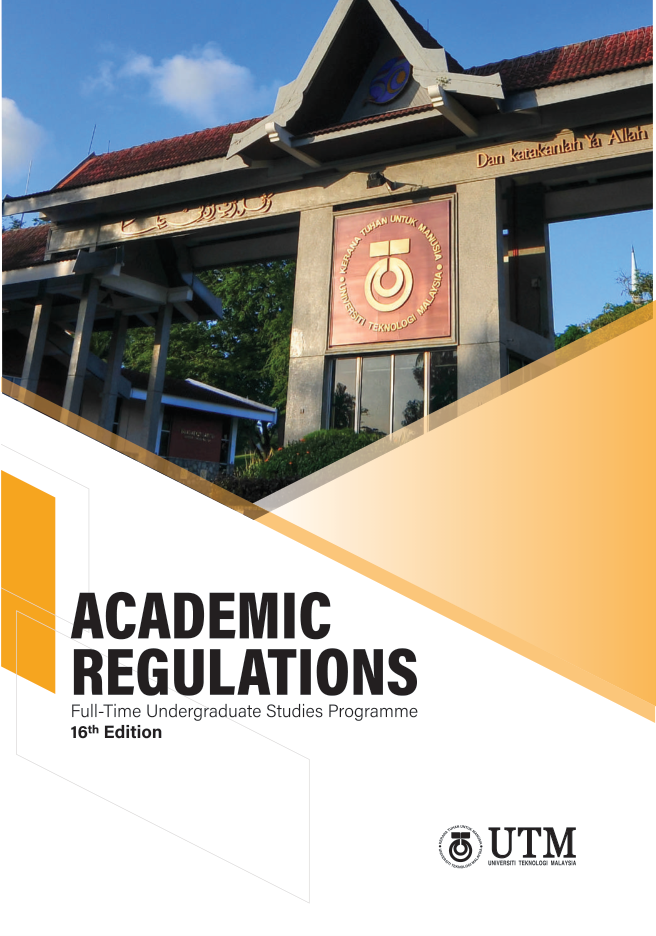


--- PDF PAGE 2 ---


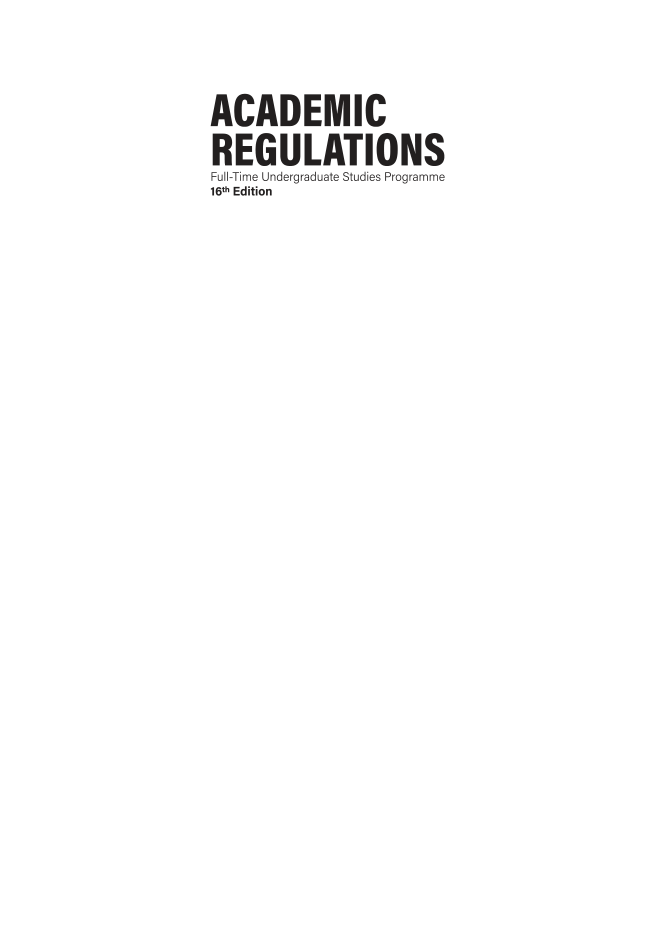


--- PDF PAGE 3 ---


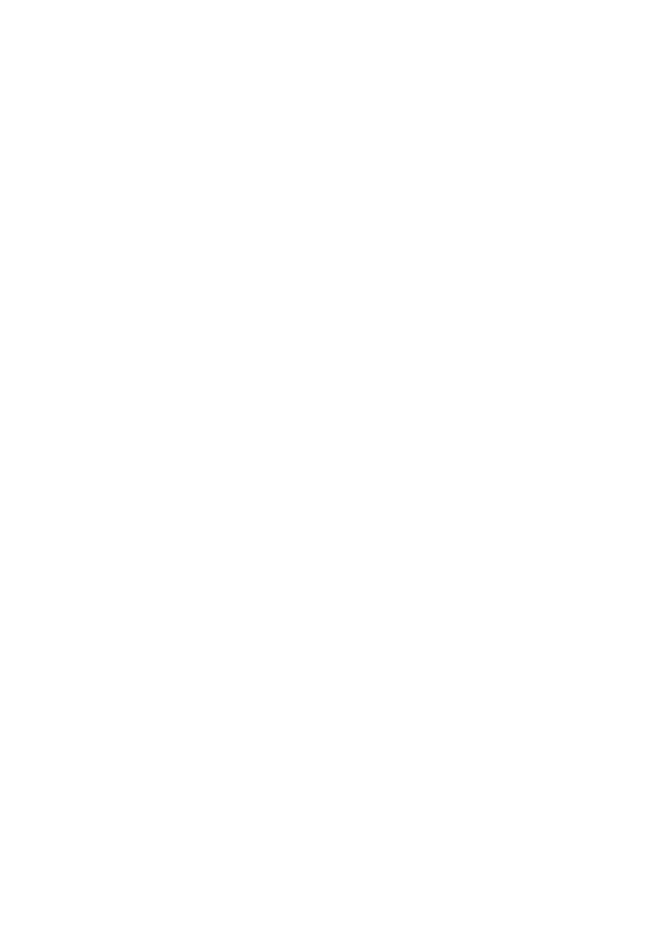


--- PDF PAGE 4 ---


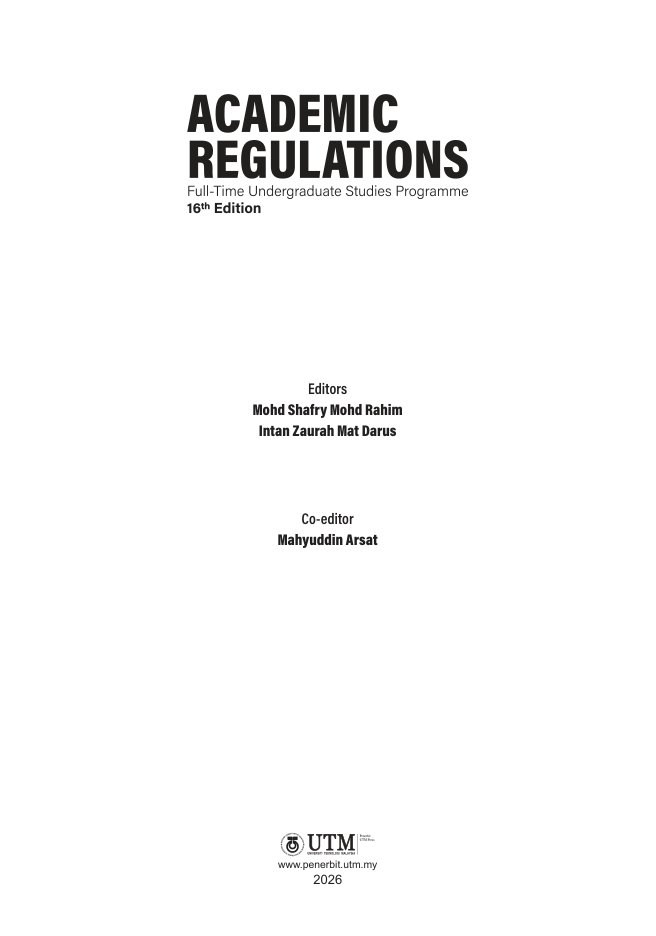


--- PDF PAGE 11 ---


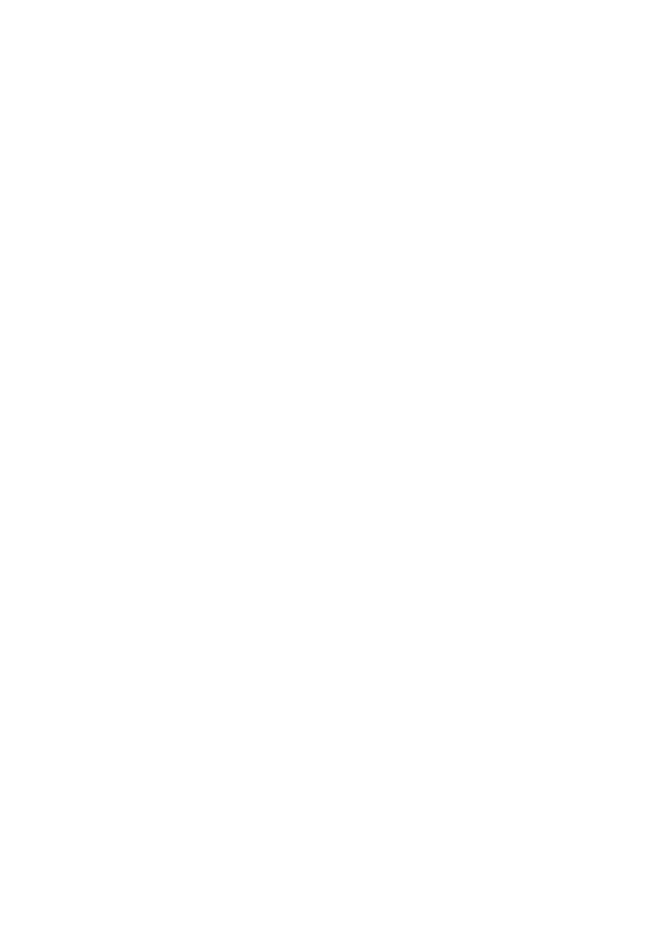


--- PDF PAGE 13 ---


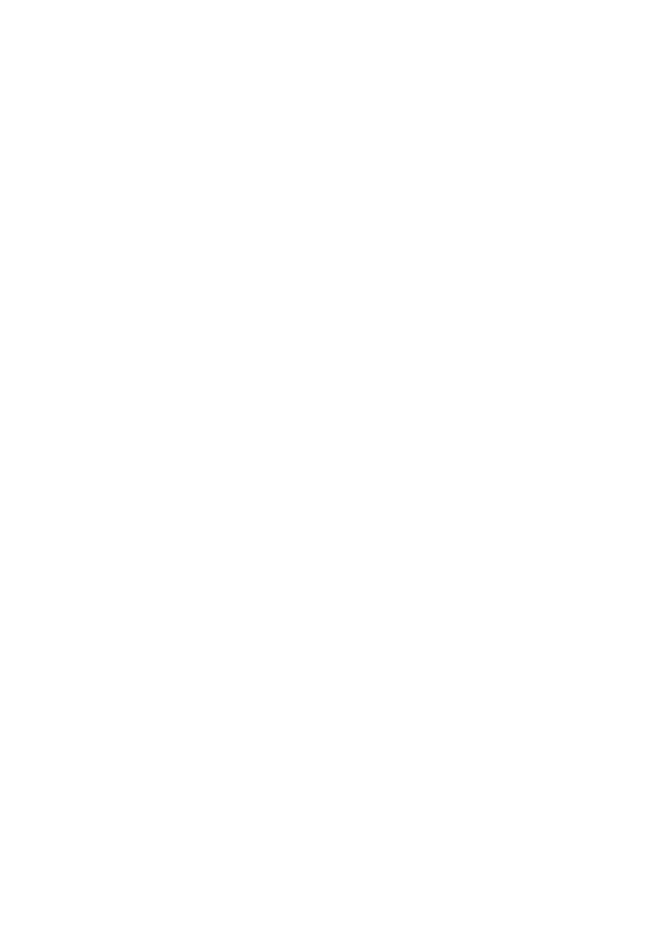


--- PDF PAGE 15 ---


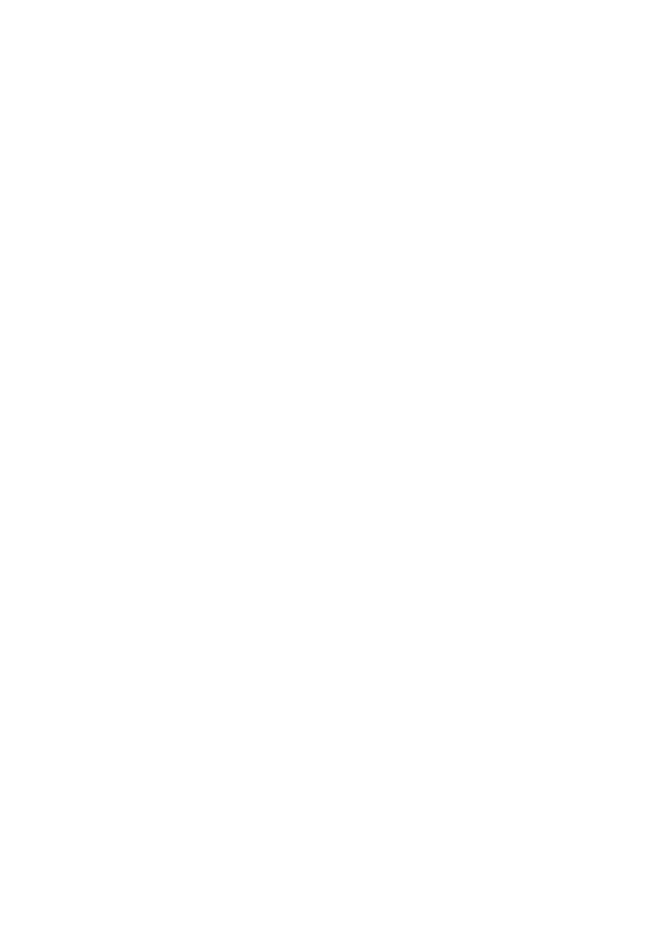


--- PDF PAGE 81 ---


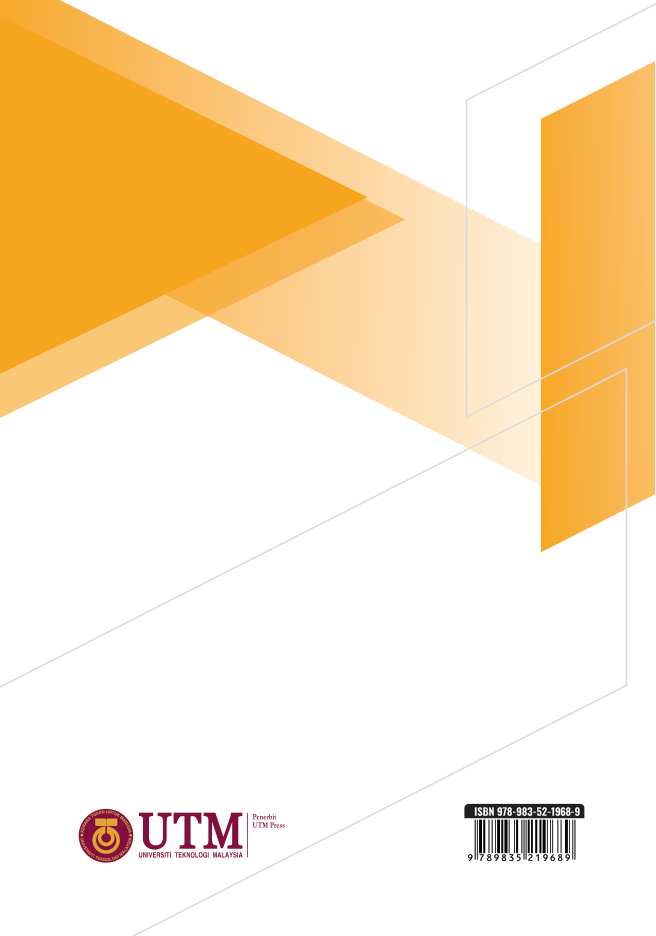

In [12]:
!pip install pymupdf -q

import fitz
from PIL import Image
from IPython.display import display

# Correct path using the RAW_DIR variable from the workspace setup
pdf_path = RAW_DIR / "academic_regulations_2026.pdf"

doc = fitz.open(str(pdf_path))

pages_to_inspect = [1, 2, 3, 4, 11, 13, 15, 81]

for page_number in pages_to_inspect:
    page = doc[page_number - 1]

    # Render page as an image
    pix = page.get_pixmap(matrix=fitz.Matrix(1.3, 1.3))
    image = Image.frombytes("RGB", [pix.width, pix.height], pix.samples)

    print(f"\n--- PDF PAGE {page_number} ---")
    display(image)


**Academic Regulations PDF – Data Quality Assessment**

The Academic Regulations PDF contains 81 pages. Initial extraction identified eight pages requiring further inspection due to blank or limited text extraction and glyph-encoding artefacts.

These pages were flagged for additional review. OCR was applied to pages with suspicious extraction results where appropriate. The recovered text was checked for readability, and pages containing no relevant information were excluded only after inspection.

The final number of pages included in the prepared dataset is determined by the page-level preparation and export process.

The PDF was processed using `pypdf`, with PyMuPDF and Tesseract OCR used as a fallback for problematic pages.

**Limitation:** OCR may introduce recognition errors, particularly in tables, numbers and complex layouts. Original PDF pages remain the reference for checking the accuracy of recovered text.


# A4 — Create the data inventory

**Cell A4.1 — Create the inventory folder**

In [13]:
from pathlib import Path

DOCS_DIR = BASE_DIR / "docs"
DOCS_DIR.mkdir(parents=True, exist_ok=True)

print("Documentation folder:", DOCS_DIR)

Documentation folder: /content/week3_project/docs


**Cell A4.2 — Generate the data inventory Markdown file**

In [14]:
# A4.2 — Updated UniGuide data inventory

inventory_content = """
# UniGuide - Week 3 Data Inventory

## Project Overview

UniGuide is a document-grounded academic information assistant
designed to help UTM students retrieve accurate academic information
from official UTM documents.

The selected data sources support the document-based RAG approach.

## Data Inventory

| Source ID | Filename | Type and Purpose | Version / Date / Owner | Access / Rights | Inspection Evidence |
|---|---|---|---|---|---|
| S01 | academic_regulations_2026.pdf | PDF - UTM academic regulations and academic policies. | 2026 / Issuing owner to be verified. | Official source and usage permissions to be verified. | Page-level extraction, GID detection, OCR fallback and representative text inspection. |
| S02 | course_registration_guide_2026_2027.pdf | PDF - Course registration procedures and student guidance. | 2026/2027 / Issuing owner to be verified. | Official source and usage permissions to be verified. | PDF text extraction and representative page inspection. |
| S03 | academic_calendar_2026_2027.pdf | PDF - Academic dates, semester schedules and university events. | 2026/2027 / Issuing owner to be verified. | Official source and usage permissions to be verified. | PDF text extraction and representative page inspection. |

## Relationship to Topic 2 Requirements

| Requirement ID | Required Information | Supporting Source | Justification |
|---|---|---|---|
| FR1 | UTM academic regulations and guidelines | S01 | Supports academic rules and policy questions. |
| FR2 | Course registration information and academic dates | S02, S03 | Supports registration procedures, deadlines and academic schedules. |
| FR3 | Official document references and citations | S01, S02, S03 | Supports source traceability and document-grounded answers. |
| FR4 | Identify unavailable information instead of generating unsupported answers | S01, S02, S03 | Defines the available knowledge coverage for answering questions. |

Note: Confirm that FR1-FR4 match the actual requirement IDs
in the Topic 2 project document.

## Data Storage

- Raw documents: data/raw/
- Prepared documents: data/processed/
- Prepared text output: data/processed/prepared_text.jsonl
- Lineage manifest: data/week3_manifest.json

Raw source PDFs are retained separately from prepared outputs.

## Preparation Process

1. Select the approved PDF source files.
2. Extract page-level text using pypdf.
3. Detect pages with suspicious extraction results.
4. Apply Tesseract OCR as a fallback where required.
5. Clean unnecessary whitespace.
6. Compare fixed-size and paragraph-aware chunking.
7. Export page-aware JSONL records with source metadata.
8. Validate the prepared output.
9. Register source-to-output lineage and checksums.

## Inspection and Limitations

- PDF text extraction may lose formatting and layout information.
- Some pages may contain scanned or image-based text.
- OCR may introduce character, number and date recognition errors.
- Tables may not preserve their original structure.
- Paragraph boundaries may not be preserved during PDF extraction.
- Source ownership, access rights and redistribution permissions
  must be verified before sharing the documents.

## Data Quality Status

The initial inspection identified extraction limitations in S01.
OCR fallback and page-level quality checks are used to improve
the prepared text.

The final dataset is considered prepared only after the
B3 validation checks have passed and representative records
have been inspected.
"""

inventory_path = DOCS_DIR / "week3_data_inventory.md"

inventory_path.write_text(
    inventory_content,
    encoding="utf-8"
)

print("Updated UniGuide data inventory created.")
print("Saved at:", inventory_path)

print("\nInventory preview:")
print(
    inventory_path.read_text(
        encoding="utf-8"
    )[:2000]
)

Updated UniGuide data inventory created.
Saved at: /content/week3_project/docs/week3_data_inventory.md

Inventory preview:

# UniGuide - Week 3 Data Inventory

## Project Overview

UniGuide is a document-grounded academic information assistant
designed to help UTM students retrieve accurate academic information
from official UTM documents.

The selected data sources support the document-based RAG approach.

## Data Inventory

| Source ID | Filename | Type and Purpose | Version / Date / Owner | Access / Rights | Inspection Evidence |
|---|---|---|---|---|---|
| S01 | academic_regulations_2026.pdf | PDF - UTM academic regulations and academic policies. | 2026 / Issuing owner to be verified. | Official source and usage permissions to be verified. | Page-level extraction, GID detection, OCR fallback and representative text inspection. |
| S02 | course_registration_guide_2026_2027.pdf | PDF - Course registration procedures and student guidance. | 2026/2027 / Issuing owner to be verified. | 

**Cell A4.3 — Verify the inventory file**

In [15]:
# Verify that the inventory exists and contains content

assert inventory_path.is_file(), "Inventory file was not created."

assert inventory_path.stat().st_size > 0, "Inventory file is empty."

print("A4 VALIDATION SUCCESSFUL")
print("Filename:", inventory_path.name)
print("File size:", inventory_path.stat().st_size, "bytes")

print("\nInventory preview:\n")

print(inventory_path.read_text(encoding="utf-8")[:1500])

A4 VALIDATION SUCCESSFUL
Filename: week3_data_inventory.md
File size: 3486 bytes

Inventory preview:


# UniGuide - Week 3 Data Inventory

## Project Overview

UniGuide is a document-grounded academic information assistant
designed to help UTM students retrieve accurate academic information
from official UTM documents.

The selected data sources support the document-based RAG approach.

## Data Inventory

| Source ID | Filename | Type and Purpose | Version / Date / Owner | Access / Rights | Inspection Evidence |
|---|---|---|---|---|---|
| S01 | academic_regulations_2026.pdf | PDF - UTM academic regulations and academic policies. | 2026 / Issuing owner to be verified. | Official source and usage permissions to be verified. | Page-level extraction, GID detection, OCR fallback and representative text inspection. |
| S02 | course_registration_guide_2026_2027.pdf | PDF - Course registration procedures and student guidance. | 2026/2027 / Issuing owner to be verified. | Official source and u

### B1 – Selection of Data Preparation Pathway

| Item | Description |
|---|---|
| Selected Pathway | Pathway A – PDF/TXT |
| Data Sources | UTM Academic Regulations, Course Registration Guidelines and Academic Calendar |
| Processing Tools | pypdf and Python |
| Preparation Methods | Text extraction, whitespace cleaning and chunking |
| Expected Output | prepared_text.jsonl |

**Explanation:**

Pathway A is selected because UniGuide uses PDF documents as its main data sources. The text will be extracted, cleaned and divided into smaller chunks to make academic information easier to process and retrieve.

# B2 — Extract, clean and prepare the documents
**Cell B2.1 — Required common metadata helper (Cell 4 from the lab)**

In [16]:
from pathlib import Path
import json
import hashlib
from datetime import datetime, timezone

def select_source(relative_path=None, filename=None, suffixes=None):

    if relative_path:
        selected = RAW_DIR / relative_path

        if not selected.is_file():
            raise FileNotFoundError(
                f"Source not found: {selected}"
            )

        return selected

    matches = sorted(
        p for p in RAW_DIR.rglob("*")
        if p.is_file()
        and (filename is None or p.name == filename)
        and (suffixes is None or p.suffix.lower() in suffixes)
    )

    print(
        "Candidates:",
        [str(p.relative_to(RAW_DIR)) for p in matches]
    )

    if len(matches) != 1:
        raise ValueError(
            "Select exactly one source using relative_path."
        )

    return matches[0]


def source_hash(path):

    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()


def save_manifest(records):

    manifest = {
        "pipeline_version": "week3-v1",
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "records": records
    }

    target = BASE_DIR / "data" / "week3_manifest.json"
    target.parent.mkdir(parents=True, exist_ok=True)

    target.write_text(
        json.dumps(
            manifest,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    print("Saved lineage:", target)

    return manifest


print("Cell 4 completed successfully.")

Cell 4 completed successfully.


**Cell B2.2 — Initialise the lineage registry (Cell 4A)**

In [17]:
lineage_entries = {}

def register_lineage(source, output, processing):

    source = Path(source).resolve()
    output = Path(output).resolve()

    if not source.is_file():
        raise FileNotFoundError(
            f"Source file not found: {source}"
        )

    if not output.is_file():
        raise FileNotFoundError(
            f"Prepared output not found: {output}"
        )

    if output.stat().st_size == 0:
        raise ValueError(
            f"Prepared output is empty: {output}"
        )

    if not isinstance(processing, str) or not processing.strip():
        raise ValueError(
            "A processing description is required."
        )

    source.relative_to(RAW_DIR.resolve())
    output.relative_to(PROCESSED_DIR.resolve())

    key = (str(source), str(output))

    lineage_entries[key] = {
        "source": source,
        "output": output,
        "processing": processing.strip()
    }

    print(
        "Registered:",
        source.name,
        "->",
        output.name
    )


print("Common lineage registry ready.")
print("Registered entries:", len(lineage_entries))

Common lineage registry ready.
Registered entries: 0


**Cell B2.3 — Select all three official UTM PDFs**

In [18]:
!pip -q install pypdf

from pypdf import PdfReader
import re

# Explicitly select the three UniGuide documents

source_files = {
    "S01": "academic_regulations_2026.pdf",
    "S02": "course_registration_guide_2026_2027.pdf",
    "S03": "academic_calendar_2026_2027.pdf"
}

selected_sources = {}

for source_id, filename in source_files.items():

    f = select_source(relative_path=filename)

    selected_sources[source_id] = f

    print(source_id, ":", f)

S01 : /content/week3_project/data/raw/academic_regulations_2026.pdf
S02 : /content/week3_project/data/raw/course_registration_guide_2026_2027.pdf
S03 : /content/week3_project/data/raw/academic_calendar_2026_2027.pdf


**Cell B2.4 — Extract and clean all three PDFs**

In [19]:
# ============================================================
# B2.4 - CELL 1: INSTALL REQUIRED LIBRARIES
# ============================================================

!apt-get -qq update
!apt-get -qq install -y tesseract-ocr

!pip -q install pymupdf pytesseract pillow pypdf

print("All required libraries installed successfully.")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
All required libraries installed successfully.


In [20]:
# ============================================================
# B2.4 - CELL 2: IMPORT LIBRARIES AND CONFIGURATION
# ============================================================

import os
import re
import fitz
import pytesseract

from PIL import Image
from io import BytesIO
from pypdf import PdfReader


# ------------------------------------------------------------
# EXTRACTION CONFIGURATION
# ------------------------------------------------------------

INITIAL_DPI = 300
RETRY_DPI = 400

MIN_WORDS = 10
MIN_OCR_WORDS = 20

# ------------------------------------------------------------
# MANUAL METHOD OVERRIDES
# ------------------------------------------------------------
# Use this dictionary only after visually inspecting the
# corresponding PDF pages.
#
# Available methods:
#   "pypdf"
#   "tesseract_ocr"
#
# Example:
# MANUAL_METHOD_OVERRIDES = {
#     "S01": {81: "tesseract_ocr"},
#     "S02": {},
#     "S03": {}
# }
#
# Leave empty until you have verified the page visually.

MANUAL_METHOD_OVERRIDES = {
    "S01": {},
    "S02": {},
    "S03": {}
}

print("Libraries imported and extraction settings configured.")

Libraries imported and extraction settings configured.


In [21]:
# ============================================================
# B2.4 - CELL 3: EXTRACTION AND OCR FUNCTIONS
# ============================================================


def word_count(text):
    """
    Count meaningful word-like tokens in extracted text.
    """

    if not text:
        return 0

    return len(re.findall(r"\b[\w-]+\b", text))


def gid_count(text):
    """
    Detect PDF font-encoding artefacts such as /gid00006.
    """

    if not text:
        return 0

    return len(re.findall(r"/gid\d+", text))


def needs_ocr(text):
    """
    Identify pages that may need OCR.

    This is a heuristic, not a guarantee of extraction quality.
    """

    if not text or not text.strip():
        return True

    if gid_count(text) > 0:
        return True

    if word_count(text) < MIN_WORDS:
        return True

    return False


def clean_text(text):
    """
    Clean extracted text without removing potentially
    meaningful academic information.
    """

    if not text:
        return ""

    # Normalise line endings
    text = text.replace("\r\n", "\n")
    text = text.replace("\r", "\n")

    # Remove null characters
    text = text.replace("\x00", "")

    # Remove repeated spaces and tabs
    text = re.sub(r"[ \t]+", " ", text)

    # Remove excessive blank lines
    text = re.sub(r"\n{3,}", "\n\n", text)

    # Remove spaces at the beginning/end of lines
    text = "\n".join(
        line.strip() for line in text.splitlines()
    )

    return text.strip()


def text_quality_score(text):
    """
    Calculate a basic heuristic score for comparing
    extracted text candidates.

    IMPORTANT:
    This score does not measure actual OCR accuracy.
    Visual inspection is still necessary.
    """

    if not text or not text.strip():
        return 0

    words = word_count(text)

    if words == 0:
        return 0

    score = words

    # Penalise PDF encoding artefacts
    score -= gid_count(text) * 10

    # Penalise excessive unusual characters
    unusual_chars = len(
        re.findall(r"[^A-Za-z0-9\s.,:;!?()/%&'\"-]", text)
    )

    score -= unusual_chars * 0.2

    # Penalise excessive repeated symbols
    repeated_symbols = len(
        re.findall(r"([^\w\s])\1{2,}", text)
    )

    score -= repeated_symbols * 2

    return max(score, 0)


def ocr_pdf_page(pdf_document, page_index, dpi=300, psm=3):
    """
    Perform OCR on one PDF page using Tesseract.

    psm=3: Fully automatic page segmentation.
    psm=6: Assume a uniform block of text.
    """

    page = pdf_document.load_page(page_index)

    zoom = dpi / 72

    matrix = fitz.Matrix(zoom, zoom)

    pixmap = page.get_pixmap(
        matrix=matrix,
        colorspace=fitz.csGRAY,
        alpha=False
    )

    image_bytes = pixmap.tobytes("png")

    image = Image.open(
        BytesIO(image_bytes)
    )

    config = f"--oem 3 --psm {psm}"

    extracted_text = pytesseract.image_to_string(
        image,
        config=config
    )

    return extracted_text


def get_best_ocr(pdf_document, page_index):
    """
    Compare OCR candidates using two page segmentation modes.

    If the initial results are weak, retry at a higher DPI.

    The selected candidate is only a heuristic choice and
    must be checked against the original PDF page.
    """

    candidates = []

    # --------------------------------------------------------
    # FIRST ATTEMPT: 300 DPI
    # --------------------------------------------------------

    for psm in [3, 6]:

        text = ocr_pdf_page(
            pdf_document,
            page_index,
            dpi=INITIAL_DPI,
            psm=psm
        )

        candidates.append({
            "text": text,
            "dpi": INITIAL_DPI,
            "psm": psm,
            "score": text_quality_score(text)
        })

    best_candidate = max(
        candidates,
        key=lambda item: item["score"]
    )

    # --------------------------------------------------------
    # SECOND ATTEMPT: 400 DPI IF INITIAL RESULT IS WEAK
    # --------------------------------------------------------

    if (
        best_candidate["score"] < 15
        or word_count(best_candidate["text"]) < MIN_OCR_WORDS
    ):

        for psm in [3, 6]:

            text = ocr_pdf_page(
                pdf_document,
                page_index,
                dpi=RETRY_DPI,
                psm=psm
            )

            candidates.append({
                "text": text,
                "dpi": RETRY_DPI,
                "psm": psm,
                "score": text_quality_score(text)
            })

    # Select the highest-scoring candidate
    best_candidate = max(
        candidates,
        key=lambda item: item["score"]
    )

    return best_candidate, candidates

In [22]:
# ============================================================
# B2.4 - CELL 4: IMPROVED PDF EXTRACTION WITH OCR FALLBACK
# ============================================================

# ------------------------------------------------------------
# IMPORTANT:
# This cell expects the PDF file paths from your A3
# document-selection section.
# ------------------------------------------------------------

# Fallback compatibility: check both pdf_files and sources
if "pdf_files" not in globals() and "sources" in globals():
    pdf_files = sources

# Check whether PDF paths are available
if "pdf_files" not in globals():
    raise NameError(
        "pdf_files was not found. "
        "Run your A3 PDF selection cell first."
    )


# ------------------------------------------------------------
# RESET DOCUMENT DATA
# ------------------------------------------------------------

document_data = {}


# ------------------------------------------------------------
# PROCESS EACH DOCUMENT
# ------------------------------------------------------------

for source_id, source_file in pdf_files.items():

    print("\n" + "=" * 70)
    print(f"PROCESSING DOCUMENT: {source_id}")
    print("=" * 70)

    if not os.path.exists(source_file):
        print(f"ERROR: File not found: {source_file}")
        continue

    # Read PDF using pypdf
    reader = PdfReader(source_file)

    # Open PDF using PyMuPDF for OCR
    pdf_document = fitz.open(source_file)

    pages = []
    page_methods = []
    review_pages = []
    page_quality = []

    # --------------------------------------------------------
    # PROCESS EACH PAGE
    # --------------------------------------------------------

    for page_index in range(len(reader.pages)):

        page_number = page_index + 1

        print(f"\nProcessing page {page_number}...")

        # ----------------------------------------------------
        # STEP 1: EXTRACT USING PYPDF
        # ----------------------------------------------------

        original_text = reader.pages[
            page_index
        ].extract_text() or ""

        original_text = original_text.strip()

        original_words = word_count(original_text)

        # ----------------------------------------------------
        # STEP 2: CHECK WHETHER OCR IS REQUIRED
        # ----------------------------------------------------

        ocr_candidate = None

        ocr_candidates = []


        if needs_ocr(original_text):

            ocr_candidate, ocr_candidates = get_best_ocr(
                pdf_document,
                page_index
            )

        # ----------------------------------------------------
        # STEP 3: SELECT EXTRACTION METHOD
        # ----------------------------------------------------

        if ocr_candidate is not None:

            ocr_text = ocr_candidate["text"]

            original_score = text_quality_score(
                original_text
            )

            ocr_score = ocr_candidate["score"]

            # Use OCR when it produces a better heuristic score
            if (
                not original_text.strip()
                or gid_count(original_text) > 0
                or ocr_score > original_score
            ):

                chosen_text = ocr_text
                method = "tesseract_ocr"

            else:

                chosen_text = original_text
                method = "pypdf"

        else:

            chosen_text = original_text
            method = "pypdf"

        # ----------------------------------------------------
        # STEP 4: APPLY MANUAL METHOD OVERRIDE
        # ----------------------------------------------------

        source_overrides = MANUAL_METHOD_OVERRIDES.get(
            source_id, {}
        )

        if page_number in source_overrides:

            override_method = source_overrides[page_number]

            if override_method == "pypdf":

                chosen_text = original_text
                method = "pypdf"

            elif override_method == "tesseract_ocr":

                # Generate OCR if it was not already generated
                if ocr_candidate is None:

                    ocr_candidate, ocr_candidates = get_best_ocr(
                        pdf_document,
                        page_index
                    )

                chosen_text = ocr_candidate["text"]
                method = "tesseract_ocr"

            else:

                raise ValueError(
                    f"Invalid override method for "
                    f"{source_id} page {page_number}"
                )

        # ----------------------------------------------------
        # STEP 5: CLEAN SELECTED TEXT
        # ----------------------------------------------------

        final_text = clean_text(chosen_text)

        final_words = word_count(final_text)

        remaining_gid = gid_count(final_text)

        # ----------------------------------------------------
        # STEP 6: GENERATE QUALITY FLAGS
        # ----------------------------------------------------

        flags = []

        if not final_text.strip():

            flags.append("NO_TEXT_RECOVERED")

        if final_words < MIN_WORDS:

            flags.append("LOW_WORD_COUNT")

        if remaining_gid > 0:

            flags.append("GID_REMAINS")

        if method == "tesseract_ocr":

            # Every OCR-selected page requires visual verification
            flags.append("OCR_MANUAL_VERIFICATION")

        if (
            method == "tesseract_ocr"
            and final_words < MIN_OCR_WORDS
        ):

            flags.append("OCR_RECOVERY_INCOMPLETE")

        # ----------------------------------------------------
        # STEP 7: SAVE PAGE DATA
        # ----------------------------------------------------

        pages.append((
            page_number,
            final_text
        ))

        page_methods.append({
            "page": page_number,
            "method": method
        })

        page_quality.append({
            "page": page_number,
            "original_words": original_words,
            "final_words": final_words,
            "gid_count": remaining_gid,
            "method": method,
            "flags": flags
        })

        # Add pages requiring inspection to review list
        if flags:

            review_pages.append({
                "page": page_number,
                "method": method,
                "original_words": original_words,
                "final_words": final_words,
                "flags": flags,
                "text": final_text
            })

        # ----------------------------------------------------
        # STEP 8: PRINT PAGE RESULT
        # ----------------------------------------------------

        print("Method:", method)
        print("Original words:", original_words)
        print("Final words:", final_words)
        print("GID patterns remaining:", remaining_gid)

        if flags:

            print("Flags:", ", ".join(flags))

        else:

            print("Flags: None")

    # --------------------------------------------------------
    # COMBINE ALL PAGE TEXT
    # --------------------------------------------------------

    full_text = "\n\n".join(
        f"[PAGE {page_number}]\n{text}"
        for page_number, text in pages
    )

    clean_full_text = clean_text(full_text)

    # --------------------------------------------------------
    # STORE DOCUMENT DATA
    # --------------------------------------------------------

    document_data[source_id] = {

        "source": source_file,

        "pages": pages,

        "text": full_text,

        "clean": clean_full_text,

        "page_methods": page_methods,

        "review_pages": review_pages,

        "page_quality": page_quality
    }

    pdf_document.close()

    # --------------------------------------------------------
    # DOCUMENT SUMMARY
    # --------------------------------------------------------

    ocr_pages = sum(
        1 for item in page_methods
        if item["method"] == "tesseract_ocr"
    )

    total_gid = gid_count(clean_full_text)

    print("\n" + "-" * 70)
    print(f"DOCUMENT SUMMARY: {source_id}")
    print("-" * 70)

    print("Filename:", os.path.basename(source_file))
    print("Total pages:", len(pages))
    print("Total characters:", len(clean_full_text))
    print("OCR pages:", ocr_pages)
    print("Pages requiring review:", len(review_pages))
    print("GID patterns remaining:", total_gid)


print("\n" + "=" * 70)
print("ALL DOCUMENTS PROCESSED")
print("=" * 70)

print("Successfully processed documents:", len(document_data))


PROCESSING DOCUMENT: S01

Processing page 1...
Method: tesseract_ocr
Original words: 0
Final words: 107
GID patterns remaining: 0
Flags: OCR_MANUAL_VERIFICATION

Processing page 2...
Method: tesseract_ocr
Original words: 0
Final words: 8
GID patterns remaining: 0
Flags: LOW_WORD_COUNT, OCR_MANUAL_VERIFICATION, OCR_RECOVERY_INCOMPLETE

Processing page 3...
Method: tesseract_ocr
Original words: 0
Final words: 0
GID patterns remaining: 0
Flags: NO_TEXT_RECOVERED, LOW_WORD_COUNT, OCR_MANUAL_VERIFICATION, OCR_RECOVERY_INCOMPLETE

Processing page 4...
Method: tesseract_ocr
Original words: 80
Final words: 29
GID patterns remaining: 0
Flags: OCR_MANUAL_VERIFICATION

Processing page 5...
Method: pypdf
Original words: 220
Final words: 220
GID patterns remaining: 0
Flags: None

Processing page 6...
Method: pypdf
Original words: 78
Final words: 78
GID patterns remaining: 0
Flags: None

Processing page 7...
Method: pypdf
Original words: 149
Final words: 149
GID patterns remaining: 0
Flags: None

P

In [23]:
# ============================================================
# B2.4 - CELL 5: EXTRACTION SUMMARY
# ============================================================

print("\nUNIGUIDE IMPROVED EXTRACTION SUMMARY")
print("=" * 75)

for source_id, data in document_data.items():

    total_pages = len(data["pages"])

    total_characters = len(data["clean"])

    ocr_pages = sum(
        1 for item in data["page_methods"]
        if item["method"] == "tesseract_ocr"
    )

    review_count = len(data["review_pages"])

    remaining_gid = gid_count(data["clean"])

    print("\nSource ID:", source_id)

    print(
        "Filename:",
        os.path.basename(data["source"])
    )

    print("Total pages:", total_pages)

    print("Extracted characters:", total_characters)

    print("OCR pages:", ocr_pages)

    print("Pages requiring review:", review_count)

    print("Remaining GID patterns:", remaining_gid)

    # --------------------------------------------------------
    # STATUS
    # --------------------------------------------------------

    if not data["clean"].strip():

        status = "EXTRACTION FAILED — OCR / INSPECTION REQUIRED"

    elif remaining_gid > 0:

        status = "GID ARTEFACTS REMAIN — REVIEW REQUIRED"

    elif review_count > 0:

        status = "EXTRACTED — MANUAL PAGE VERIFICATION REQUIRED"

    else:

        status = "EXTRACTED — CONTENT REVIEW STILL REQUIRED"

    print("Status:", status)

print("\n" + "=" * 75)
print("SUMMARY COMPLETED")


UNIGUIDE IMPROVED EXTRACTION SUMMARY

Source ID: S01
Filename: academic_regulations_2026.pdf
Total pages: 81
Extracted characters: 104530
OCR pages: 6
Pages requiring review: 8
Remaining GID patterns: 0
Status: EXTRACTED — MANUAL PAGE VERIFICATION REQUIRED

Source ID: S02
Filename: course_registration_guide_2026_2027.pdf
Total pages: 10
Extracted characters: 3573
OCR pages: 1
Pages requiring review: 2
Remaining GID patterns: 0
Status: EXTRACTED — MANUAL PAGE VERIFICATION REQUIRED

Source ID: S03
Filename: academic_calendar_2026_2027.pdf
Total pages: 2
Extracted characters: 8172
OCR pages: 0
Pages requiring review: 0
Remaining GID patterns: 0
Status: EXTRACTED — CONTENT REVIEW STILL REQUIRED

SUMMARY COMPLETED


In [24]:
# ============================================================
# B2.4 - CELL 6: MANUAL VERIFICATION REPORT
# ============================================================

print("\nPAGES REQUIRING MANUAL VERIFICATION")
print("=" * 75)

for source_id, data in document_data.items():

    print(f"\nSOURCE: {source_id}")

    if not data["review_pages"]:

        print("No pages were automatically flagged.")

        continue

    for item in data["review_pages"]:

        print("\nPage:", item["page"])

        print("Method:", item["method"])

        print("Original words:", item["original_words"])

        print("Final words:", item["final_words"])

        print("Flags:", ", ".join(item["flags"]))

        print("\nExtracted text preview:")

        print(item["text"][:500])

        print("-" * 60)


print("\nManual verification report completed.")


PAGES REQUIRING MANUAL VERIFICATION

SOURCE: S01

Page: 1
Method: tesseract_ocr
Original words: 0
Final words: 107
Flags: OCR_MANUAL_VERIFICATION

Extracted text preview:
ite a — Fr} al j
oa to _ “te or] + 24 % i —— : a _—
a ee FZ = iz
/ Joe vO 3 aa -_ off af Any
ve _ ae Paha 5 ———
| ? Y/ ‘ os ————— i
~ a , __———
Same =: » az mga enren, |
tee a3 | es, 2
—_—y i a 4 > —
_ 4 women 7, p ie ol‘
“ a s) il ae Se
> | a, : ~ = , te ile
| 7 a a t i TERNOUD , . , ; =H
fy | ’ ! ¢ ws l = . =i
4 E 4 i “ ai Is 2 i
e | hei ' ai i! es “g
q i ij ia q 4
: J. 5p
Full-Time Undergraduate Studies Programme
16th Edition
OO UNIVERSITI TEKNOLOGI MALAYSIA
------------------------------------------------------------

Page: 2
Method: tesseract_ocr
Original words: 0
Final words: 8
Flags: LOW_WORD_COUNT, OCR_MANUAL_VERIFICATION, OCR_RECOVERY_INCOMPLETE

Extracted text preview:
ACADEMIC
REGULATIONS

Full-Time Undergraduate Studies Programme
16% Edition
------------------------------------------------------------

Pa

In [25]:
# ============================================================
# B2.4 - CELL 7: REPRESENTATIVE PAGE INSPECTION
# ============================================================

print("\nREPRESENTATIVE EXTRACTED PAGES")
print("=" * 75)

for source_id, data in document_data.items():

    print(f"\nSOURCE: {source_id}")

    # Select the first non-empty page as an initial sample
    representative_page = None

    for page_number, page_text in data["pages"]:

        if page_text.strip():

            representative_page = (
                page_number,
                page_text
            )

            break

    if representative_page is None:

        print("No non-empty page available.")

        continue

    page_number, page_text = representative_page

    print("\nRepresentative page:", page_number)

    print("-" * 60)

    print(page_text[:1500])

    print("-" * 60)


print("\nRepresentative page inspection completed.")


REPRESENTATIVE EXTRACTED PAGES

SOURCE: S01

Representative page: 1
------------------------------------------------------------
ite a — Fr} al j
oa to _ “te or] + 24 % i —— : a _—
a ee FZ = iz
/ Joe vO 3 aa -_ off af Any
ve _ ae Paha 5 ———
| ? Y/ ‘ os ————— i
~ a , __———
Same =: » az mga enren, |
tee a3 | es, 2
—_—y i a 4 > —
_ 4 women 7, p ie ol‘
“ a s) il ae Se
> | a, : ~ = , te ile
| 7 a a t i TERNOUD , . , ; =H
fy | ’ ! ¢ ws l = . =i
4 E 4 i “ ai Is 2 i
e | hei ' ai i! es “g
q i ij ia q 4
: J. 5p
Full-Time Undergraduate Studies Programme
16th Edition
OO UNIVERSITI TEKNOLOGI MALAYSIA
------------------------------------------------------------

SOURCE: S02

Representative page: 1
------------------------------------------------------------
Step-by-step
COURSE
REGISTRATION
Bachelor Degree (Fulltime)
Senior Student
------------------------------------------------------------

SOURCE: S03

Representative page: 1
------------------------------------------------------------
DATE PROGRA

In [26]:
# Inspect all pages that required OCR or further review

for source_id, data in document_data.items():

    print("\n" + "#" * 70)
    print("SOURCE:", source_id)

    for item in data["review_pages"]:

        page_number = item["page"]

        page_text = data["pages"][page_number - 1][1]

        print("\nPAGE:", page_number)
        print("Selected method:", item["method"])
        print("Original words:", item["original_words"])
        print("Final words:", item["final_words"])

        print("\nRecovered text:")
        print(page_text[:1000])

        if not page_text.strip():
            print("WARNING: No text recovered. Inspect the original page.")


######################################################################
SOURCE: S01

PAGE: 1
Selected method: tesseract_ocr
Original words: 0
Final words: 107

Recovered text:
ite a — Fr} al j
oa to _ “te or] + 24 % i —— : a _—
a ee FZ = iz
/ Joe vO 3 aa -_ off af Any
ve _ ae Paha 5 ———
| ? Y/ ‘ os ————— i
~ a , __———
Same =: » az mga enren, |
tee a3 | es, 2
—_—y i a 4 > —
_ 4 women 7, p ie ol‘
“ a s) il ae Se
> | a, : ~ = , te ile
| 7 a a t i TERNOUD , . , ; =H
fy | ’ ! ¢ ws l = . =i
4 E 4 i “ ai Is 2 i
e | hei ' ai i! es “g
q i ij ia q 4
: J. 5p
Full-Time Undergraduate Studies Programme
16th Edition
OO UNIVERSITI TEKNOLOGI MALAYSIA

PAGE: 2
Selected method: tesseract_ocr
Original words: 0
Final words: 8

Recovered text:
ACADEMIC
REGULATIONS

Full-Time Undergraduate Studies Programme
16% Edition

PAGE: 3
Selected method: tesseract_ocr
Original words: 0
Final words: 0

Recovered text:


PAGE: 4
Selected method: tesseract_ocr
Original words: 80
Final words: 29

Recovered text:
ACADEMIC


In [27]:
# Flag pages requiring manual content verification
# We can use the variables available from the last processed page in the previous loop

try:
    # Use word_count function on original_text or verify via variables
    manual_review = (
        bool(re.search(r"/gid\d+", original_text))
        or original_words < 10
        or final_words < 20  # changed ocr_words to final_words as a proxy from the last loop run
    )

    if manual_review:
        print("QUALITY REVIEW: REQUIRED")
    else:
        print("QUALITY REVIEW: INITIAL CHECK PASSED")
except NameError as e:
    print(f"Error: Missing expected variables. Please ensure the extraction loop has run first. ({e})")

QUALITY REVIEW: INITIAL CHECK PASSED


**Cell B2.5 — Compare fixed-size and paragraph-aware chunking**

In [28]:
# B2.5 — Compare both chunking approaches page by page

def fixed_chunks(s, size=500):

    if size <= 0:
        raise ValueError("Chunk size must be positive.")

    return [
        s[i:i + size]
        for i in range(0, len(s), size)
    ]


def paragraph_chunks(s, size=500):

    if size <= 0:
        raise ValueError("Chunk size must be positive.")

    parts = []
    current = ""

    for segment in re.split(r"\n\s*\n", s):

        segment = segment.strip()

        if not segment:
            continue

        if len(segment) > size:

            if current:
                parts.append(current)
                current = ""

            parts.extend(
                fixed_chunks(segment, size)
            )

        elif len(current) + len(segment) + (
            2 if current else 0
        ) <= size:

            current += (
                "\n\n" if current else ""
            ) + segment

        else:

            if current:
                parts.append(current)

            current = segment

    if current:
        parts.append(current)

    return parts


CHUNK_SIZE = 500

chunk_comparison = {}

for source_id, data in document_data.items():

    fixed_results = []
    paragraph_results = []

    # Use exactly the same page text for both methods
    for page_number, page_text in data["pages"]:

        clean_page = re.sub(
            r"[ \t]+",
            " ",
            page_text
        ).strip()

        if not clean_page:
            continue

        fixed_results.extend(
            fixed_chunks(
                clean_page,
                CHUNK_SIZE
            )
        )

        paragraph_results.extend(
            paragraph_chunks(
                clean_page,
                CHUNK_SIZE
            )
        )

    chunk_comparison[source_id] = {
        "fixed": fixed_results,
        "paragraph-aware": paragraph_results
    }

    print("\n" + "=" * 60)
    print("SOURCE:", source_id)

    print(
        "Fixed-size chunks:",
        len(fixed_results)
    )

    print(
        "Paragraph-aware chunks:",
        len(paragraph_results)
    )

    if fixed_results:
        print("\nFixed-size sample:")
        print(fixed_results[0][:300])

    if paragraph_results:
        print("\nParagraph-aware sample:")
        print(paragraph_results[0][:300])

print("\nPage-level chunking comparison completed.")


SOURCE: S01
Fixed-size chunks: 249
Paragraph-aware chunks: 251

Fixed-size sample:
ite a — Fr} al j
oa to _ “te or] + 24 % i —— : a _—
a ee FZ = iz
/ Joe vO 3 aa -_ off af Any
ve _ ae Paha 5 ———
| ? Y/ ‘ os ————— i
~ a , __———
Same =: » az mga enren, |
tee a3 | es, 2
—_—y i a 4 > —
_ 4 women 7, p ie ol‘
“ a s) il ae Se
> | a, : ~ = , te ile
| 7 a a t i TERNOUD , . , ; =H
fy | ’ ! 

Paragraph-aware sample:
ite a — Fr} al j
oa to _ “te or] + 24 % i —— : a _—
a ee FZ = iz
/ Joe vO 3 aa -_ off af Any
ve _ ae Paha 5 ———
| ? Y/ ‘ os ————— i
~ a , __———
Same =: » az mga enren, |
tee a3 | es, 2
—_—y i a 4 > —
_ 4 women 7, p ie ol‘
“ a s) il ae Se
> | a, : ~ = , te ile
| 7 a a t i TERNOUD , . , ; =H
fy | ’ ! 

SOURCE: S02
Fixed-size chunks: 14
Paragraph-aware chunks: 17

Fixed-size sample:
Step-by-step
COURSE
REGISTRATION
Bachelor Degree (Fulltime)
Senior Student

Paragraph-aware sample:
Step-by-step
COURSE
REGISTRATION
Bachelor Degree (Fulltime)
Senior Student

SOURCE: S03
Fixed-size chunks: 

**Cell B2.6 — Display the comparison results**

In [29]:
print("CHUNKING COMPARISON RESULTS")
print("=" * 65)

for source_id, results in chunk_comparison.items():

    fixed = results["fixed"]
    structured = results["paragraph-aware"]

    print(f"\nDocument: {source_id}")

    print("Fixed-size:")
    print("  Total chunks:", len(fixed))
    print(
        "  Average characters:",
        round(
            sum(len(c) for c in fixed) / len(fixed),
            2
        )
    )

    print("Paragraph-aware:")
    print("  Total chunks:", len(structured))
    print(
        "  Average characters:",
        round(
            sum(len(c) for c in structured) / len(structured),
            2
        )
    )

CHUNKING COMPARISON RESULTS

Document: S01
Fixed-size:
  Total chunks: 249
  Average characters: 415.98
Paragraph-aware:
  Total chunks: 251
  Average characters: 412.58

Document: S02
Fixed-size:
  Total chunks: 14
  Average characters: 247.43
Paragraph-aware:
  Total chunks: 17
  Average characters: 203.29

Document: S03
Fixed-size:
  Total chunks: 17
  Average characters: 479.53
Paragraph-aware:
  Total chunks: 17
  Average characters: 479.53


**Cell B2.7 — Choose the preparation method and export JSONL**

In [30]:
# B2.7 — Final page-aware preparation and JSONL export

import json
import re

CHOSEN_METHOD = "paragraph-aware"
CHUNK_SIZE = 500

# Whitelist visually confirmed empty pages to allow the export script to run
APPROVED_EMPTY_PAGES = {("S01", 3), ("S01", 15)}


if CHOSEN_METHOD not in [
    "fixed",
    "paragraph-aware"
]:
    raise ValueError("Invalid chunking method.")


# Step 1 — Identify empty pages that need a decision

empty_pages = []

for source_id, data in document_data.items():

    for page_number, page_text in data["pages"]:

        if not page_text.strip():

            empty_pages.append(
                (source_id, page_number)
            )


unapproved_empty_pages = [
    page
    for page in empty_pages
    if page not in APPROVED_EMPTY_PAGES
]


print("Empty pages detected:", empty_pages)


if unapproved_empty_pages:

    raise ValueError(
        "Some pages have no recovered text. "
        "Visually inspect these pages. If they are "
        "genuinely blank or irrelevant, add their "
        "source/page pairs to APPROVED_EMPTY_PAGES: "
        f"{unapproved_empty_pages}"
    )


# Step 2 — Generate page-aware chunks

records = []

for source_id, data in document_data.items():

    source_file = data["source"]

    for page_number, page_text in data["pages"]:

        if not page_text.strip():

            # Only approved empty pages reach this point
            continue

        # Do not allow corrupted GID text into the dataset
        if re.search(r"/gid\d+", page_text):

            raise ValueError(
                f"GID artefact still exists in "
                f"{source_id}, page {page_number}. "
                "Review OCR before exporting."
            )

        clean_page = re.sub(
            r"[ \t]+",
            " ",
            page_text
        ).strip()

        # Apply the selected chunking method
        if CHOSEN_METHOD == "paragraph-aware":

            chunks = paragraph_chunks(
                clean_page,
                size=CHUNK_SIZE
            )

        else:

            chunks = fixed_chunks(
                clean_page,
                size=CHUNK_SIZE
            )

        # Store traceable page-level records
        for chunk_number, chunk in enumerate(
            chunks,
            start=1
        ):

            if not chunk.strip():
                continue

            records.append({

                "record_id": (
                    f"{source_id}-P{page_number:03d}-"
                    f"{chunk_number:03d}"
                ),

                "source_id": source_id,

                "text": chunk,

                "source": str(
                    source_file.relative_to(RAW_DIR)
                ),

                "source_sha256": source_hash(
                    source_file
                ),

                "processing": (
                    f"{CHOSEN_METHOD}-char-{CHUNK_SIZE}"
                ),

                "page": page_number,

                "extraction_method": (
                    data["page_methods"][page_number - 1]["method"]
                )
            })


# Step 3 — Export final JSONL

prepared_path = (
    PROCESSED_DIR / "prepared_text.jsonl"
)

prepared_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

with prepared_path.open(
    "w",
    encoding="utf-8"
) as output:

    for record in records:

        output.write(
            json.dumps(
                record,
                ensure_ascii=False
            ) + "\n"
        )


# Step 4 — Display export summary

print("\n" + "=" * 60)
print("FINAL PAGE-AWARE PREPARATION COMPLETED")
print("=" * 60)

print("Selected method:", CHOSEN_METHOD)
print("Chunk size:", CHUNK_SIZE)
print("Total chunks:", len(records))
print("Total empty pages approved:", len(APPROVED_EMPTY_PAGES))
print("Output:", prepared_path)
print("File size:", prepared_path.stat().st_size, "bytes")

print("\nChunks by source:")

for source_id in selected_sources:

    count = sum(
        1 for record in records
        if record["source_id"] == source_id
    )

    print(source_id, ":", count)

Empty pages detected: [('S01', 3), ('S01', 15)]

FINAL PAGE-AWARE PREPARATION COMPLETED
Selected method: paragraph-aware
Chunk size: 500
Total chunks: 285
Total empty pages approved: 2
Output: /content/week3_project/data/processed/prepared_text.jsonl
File size: 196609 bytes

Chunks by source:
S01 : 251
S02 : 17
S03 : 17


# B3 — Validate the prepared output and compare approaches
**Cell B3.1 — Validate prepared_text.jsonl**

In [31]:
# B3.1 — Validate the final prepared dataset

import json
import re

# Step 1 — Check output file

assert prepared_path.exists(), (
    "Prepared output is missing."
)

assert prepared_path.stat().st_size > 0, (
    "Prepared output is empty."
)


# Step 2 — Load JSONL records

with prepared_path.open(
    "r",
    encoding="utf-8"
) as file:

    exported_records = [
        json.loads(line)
        for line in file
        if line.strip()
    ]


assert exported_records, (
    "No prepared records found."
)


# Step 3 — Validate text

empty_records = [
    r for r in exported_records
    if not r.get("text", "").strip()
]

gid_records = [
    r for r in exported_records
    if re.search(
        r"/gid\d+",
        r.get("text", "")
    )
]

assert not empty_records, (
    f"Empty text records found: {len(empty_records)}"
)

assert not gid_records, (
    f"GID artefacts found: {len(gid_records)}"
)


# Step 4 — Validate source IDs

valid_source_ids = set(selected_sources.keys())

unknown_sources = [
    r for r in exported_records
    if r.get("source_id") not in valid_source_ids
]

assert not unknown_sources, (
    "Unknown source IDs found."
)


# Step 5 — Validate page numbers

missing_pages = [
    r for r in exported_records
    if not isinstance(r.get("page"), int)
    or r["page"] < 1
]

assert not missing_pages, (
    f"Missing or invalid page numbers: {len(missing_pages)}"
)


# Step 6 — Validate checksums against original files

for source_id, source_file in selected_sources.items():

    expected_hash = source_hash(source_file)

    source_records = [
        r for r in exported_records
        if r["source_id"] == source_id
    ]

    assert source_records, (
        f"No records found for {source_id}"
    )

    assert all(
        r["source_sha256"] == expected_hash
        for r in source_records
    ), (
        f"Checksum mismatch for {source_id}"
    )


# Step 7 — Validate unique record IDs

record_ids = [
    r["record_id"]
    for r in exported_records
]

assert len(record_ids) == len(set(record_ids)), (
    "Duplicate record IDs found."
)


# Step 8 — Display validation results

print("=" * 65)
print("B3.1 FINAL DATA VALIDATION: PASS")
print("=" * 65)

print("Prepared file:", prepared_path)
print("File size:", prepared_path.stat().st_size, "bytes")
print("Total records:", len(exported_records))
print("Empty records:", len(empty_records))
print("GID records:", len(gid_records))
print("Missing page numbers:", len(missing_pages))
print("Unique record IDs:", len(set(record_ids)))

print(
    "Sources represented:",
    sorted(set(
        r["source_id"]
        for r in exported_records
    ))
)

print("\nAll structural validation checks passed.")
print("Manual OCR quality review is still required.")

B3.1 FINAL DATA VALIDATION: PASS
Prepared file: /content/week3_project/data/processed/prepared_text.jsonl
File size: 196609 bytes
Total records: 285
Empty records: 0
GID records: 0
Missing page numbers: 0
Unique record IDs: 285
Sources represented: ['S01', 'S02', 'S03']

All structural validation checks passed.
Manual OCR quality review is still required.


**Cell B3.2 — Inspect representative prepared records**

In [32]:
# B3.2 — Inspect representative prepared records

for source_id in sorted(selected_sources.keys()):

    # Select the first available record from each source
    record = next(
        (
            r for r in exported_records
            if r["source_id"] == source_id
        ),
        None
    )

    if record is None:
        print("No records found for:", source_id)
        continue

    print("\n" + "=" * 70)
    print("REPRESENTATIVE RECORD")
    print("=" * 70)

    print("Record ID:", record["record_id"])
    print("Source ID:", record["source_id"])
    print("Source:", record["source"])
    print("Page:", record["page"])
    print("Processing:", record["processing"])
    print("Extraction method:", record["extraction_method"])

    print("\nPrepared text:")
    print(record["text"])

    if re.search(r"/gid\d+", record["text"]):

        print("\nQUALITY STATUS: FAILED — GID artefacts found.")

    elif record["text"].strip():

        print("\nQUALITY STATUS: PASSED — non-empty text, no GID artefacts.")

    else:

        print("\nQUALITY STATUS: FAILED — empty text.")


REPRESENTATIVE RECORD
Record ID: S01-P001-001
Source ID: S01
Source: academic_regulations_2026.pdf
Page: 1
Processing: paragraph-aware-char-500
Extraction method: tesseract_ocr

Prepared text:
ite a — Fr} al j
oa to _ “te or] + 24 % i —— : a _—
a ee FZ = iz
/ Joe vO 3 aa -_ off af Any
ve _ ae Paha 5 ———
| ? Y/ ‘ os ————— i
~ a , __———
Same =: » az mga enren, |
tee a3 | es, 2
—_—y i a 4 > —
_ 4 women 7, p ie ol‘
“ a s) il ae Se
> | a, : ~ = , te ile
| 7 a a t i TERNOUD , . , ; =H
fy | ’ ! ¢ ws l = . =i
4 E 4 i “ ai Is 2 i
e | hei ' ai i! es “g
q i ij ia q 4
: J. 5p
Full-Time Undergraduate Studies Programme
16th Edition
OO UNIVERSITI TEKNOLOGI MALAYSIA

QUALITY STATUS: PASSED — non-empty text, no GID artefacts.

REPRESENTATIVE RECORD
Record ID: S02-P001-001
Source ID: S02
Source: course_registration_guide_2026_2027.pdf
Page: 1
Processing: paragraph-aware-char-500
Extraction method: pypdf

Prepared text:
Step-by-step
COURSE
REGISTRATION
Bachelor Degree (Fulltime)
Senior Student

QUALITY 

**Cell B3.3 — Compare the two approaches and record your decision**

In [33]:
print("B3 CHUNKING APPROACH COMPARISON")
print("=" * 65)

for source_id, results in chunk_comparison.items():

    fixed = results["fixed"]
    structured = results["paragraph-aware"]

    print(f"\nSource: {source_id}")

    print(
        "Fixed-size chunk count:",
        len(fixed)
    )

    print(
        "Paragraph-aware chunk count:",
        len(structured)
    )

    print(
        "Fixed average length:",
        round(sum(map(len, fixed)) / len(fixed), 2)
    )

    print(
        "Paragraph-aware average length:",
        round(sum(map(len, structured)) / len(structured), 2)
    )

print("\nSELECTED APPROACH:", CHOSEN_METHOD)
print("REASON: Selected to preserve paragraph context for academic information retrieval.")
print("LIMITATION: Long paragraphs may still be split.")

B3 CHUNKING APPROACH COMPARISON

Source: S01
Fixed-size chunk count: 249
Paragraph-aware chunk count: 251
Fixed average length: 415.98
Paragraph-aware average length: 412.58

Source: S02
Fixed-size chunk count: 14
Paragraph-aware chunk count: 17
Fixed average length: 247.43
Paragraph-aware average length: 203.29

Source: S03
Fixed-size chunk count: 17
Paragraph-aware chunk count: 17
Fixed average length: 479.53
Paragraph-aware average length: 479.53

SELECTED APPROACH: paragraph-aware
REASON: Selected to preserve paragraph context for academic information retrieval.
LIMITATION: Long paragraphs may still be split.



### B3.3 — Chunking Approach Decision

Paragraph-aware chunking was selected for UniGuide because the system processes academic regulations, course registration guidelines and academic calendars. Preserving paragraph context helps maintain the relationship between related sentences and information.

Fixed-size chunking was also evaluated using the same source pages and a chunk size of 500 characters. The comparison considered the resulting number of chunks, average chunk length and the readability of representative samples.

Based on the observed results, paragraph-aware chunking was selected as the preferred preparation approach because it attempts to preserve paragraph boundaries while keeping the text within the selected chunk size.

**Benefit:** Related academic information is more likely to remain together within a chunk, supporting document-based information retrieval.

**Limitation:** The method uses a basic paragraph-separation heuristic. PDF extraction may not preserve original paragraph boundaries, and paragraphs longer than 500 characters may still be split.


# B4 — Preserve metadata, lineage and export
**Cell B4.1 — Register the three source documents**

In [34]:
# B4.1 — Register source-to-output lineage

# Reset registry before registering the final pipeline
lineage_entries = {}

for source_id, source_file in selected_sources.items():

    register_lineage(
        source=source_file,
        output=prepared_path,
        processing=(
            f"source_id={source_id}; "
            "PDF text extraction using pypdf; "
            "Tesseract OCR fallback for suspicious pages; "
            "whitespace cleaning; "
            f"{CHOSEN_METHOD} chunking; "
            f"chunk_size={CHUNK_SIZE}; "
            "page-level metadata preservation; "
            "JSONL export; "
            "B3 validation"
        )
    )

print("\nB4.1 completed successfully.")

print(
    "Registered lineage entries:",
    len(lineage_entries)
)

assert len(lineage_entries) == len(selected_sources), (
    "Lineage registration count does not match source count."
)

Registered: academic_regulations_2026.pdf -> prepared_text.jsonl
Registered: course_registration_guide_2026_2027.pdf -> prepared_text.jsonl
Registered: academic_calendar_2026_2027.pdf -> prepared_text.jsonl

B4.1 completed successfully.
Registered lineage entries: 3


**Cell B4.2 — Generate the common lineage manifest (Cell 6A)**

In [35]:
# CELL 6A — GENERATE COMMON LINEAGE MANIFEST

assert lineage_entries, (
    "No lineage entries registered. "
    "Register at least one selected pathway first."
)

lineage_records = []

for i, entry in enumerate(lineage_entries.values(), 1):

    source = entry["source"]
    output = entry["output"]
    processing = entry["processing"]

    # Validate registered files

    assert source.is_file(), f"Missing source: {source}"

    assert output.is_file(), f"Missing output: {output}"

    assert output.stat().st_size > 0, "Empty output"

    lineage_records.append({

        "source_id": f"S{i:02d}",

        "source_filename": str(
            source.relative_to(RAW_DIR.resolve())
        ),

        "source_sha256": source_hash(source),

        "prepared_output": str(
            output.relative_to(BASE_DIR.resolve())
        ),

        "prepared_sha256": source_hash(output),

        "processing_note": processing,

        "source_version": "Not verified",

        "access_rights": "Not verified",

        "status": "Prepared; quality review pending"
    })


# Save common manifest

manifest = save_manifest(lineage_records)

print("\nCOMMON LINEAGE MANIFEST GENERATED")

print(
    "Total lineage entries:",
    len(manifest["records"])
)

print(
    "Saved to:",
    BASE_DIR / "data" / "week3_manifest.json"
)

Saved lineage: /content/week3_project/data/week3_manifest.json

COMMON LINEAGE MANIFEST GENERATED
Total lineage entries: 3
Saved to: /content/week3_project/data/week3_manifest.json


**Cell B4.3 — Verify the saved manifest (Cell 6B)**

In [36]:
# CELL 6B — VERIFY COMMON LINEAGE MANIFEST

import json

manifest_path = BASE_DIR / "data" / "week3_manifest.json"

assert manifest_path.is_file(), (
    "Common lineage manifest not found."
)

# Read manifest

with manifest_path.open("r", encoding="utf-8") as file:

    saved_manifest = json.load(file)

saved_records = saved_manifest.get("records", [])

assert saved_records, (
    "No lineage records found in saved manifest."
)

assert len(saved_records) == len(lineage_entries), (
    "Saved lineage count does not match registration."
)

# Verify every source and prepared output

for record in saved_records:

    source = RAW_DIR / record["source_filename"]

    output = BASE_DIR / record["prepared_output"]

    assert source.is_file(), (
        f"Missing source: {source}"
    )

    assert output.is_file(), (
        f"Missing output: {output}"
    )

    assert source_hash(source) == record["source_sha256"], (
        f"Source checksum mismatch: {source}"
    )

    assert source_hash(output) == record["prepared_sha256"], (
        f"Prepared output checksum mismatch: {output}"
    )


print("COMMON LINEAGE VALIDATION: PASS")

print("Verified records:", len(saved_records))

print("Manifest:", manifest_path)

COMMON LINEAGE VALIDATION: PASS
Verified records: 3
Manifest: /content/week3_project/data/week3_manifest.json



# PART C — BUILD AND DOCUMENT THE V1 DATA PIPELINE

This section implements the V1 data pipeline for UniGuide using
the three official UTM academic PDF documents.

The pipeline follows the selected PDF/TXT preparation pathway
from Part B, including document extraction, text cleaning,
page-level validation, paragraph-aware chunking, prepared
data storage and provenance recording.



### C1.1 — Cell 7: Common V1 Pipeline Utilities

This cell defines reusable functions for source selection,
pipeline execution, SHA-256 fingerprinting, output validation,
and pipeline lineage registration.

The utilities will be used to execute the UniGuide PDF/TXT
data preparation pipeline.


In [37]:

# Cell 7 — REQUIRED: Common V1 Pipeline Utilities
# Adapted from Topic 3 Lab for UniGuide

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

# Step 1: Define standard project paths
BASE_DIR = Path("/content/week3_project")
RAW_DIR = BASE_DIR / "data" / "raw"
PIPE_DIR = BASE_DIR / "data" / "pipeline_v1"

PIPE_DIR.mkdir(parents=True, exist_ok=True)

# Store registered pipeline runs for repeatability verification
PIPELINE_RUNS = {}


# Step 2: Calculate SHA-256 checksum
def sha256_file(path):
    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()


# Step 3: Resolve an explicitly selected source
def resolve_source(relative_path, folder=False):
    source = RAW_DIR / relative_path

    if folder:
        if not source.is_dir():
            raise FileNotFoundError(
                f"Source folder not found: {source}"
            )
    else:
        if not source.is_file():
            raise FileNotFoundError(
                f"Source file not found: {source}"
            )

    return source


# Step 4: Execute the selected V1 data pipeline
def execute_pipeline(
    kind,
    source,
    inspect_fn,
    prepare_fn,
    configuration
):
    source = Path(source)

    # INGEST: Identify relevant source files
    if kind == "images":
        inputs = sorted(
            p for p in source.iterdir()
            if p.is_file()
            and p.suffix.lower() in {
                ".png", ".jpg", ".jpeg", ".webp"
            }
        )
    else:
        inputs = [source]

    if not inputs or any(not p.is_file() for p in inputs):
        raise ValueError(
            "No valid source files to ingest."
        )

    # INSPECT: Apply data-type-specific inspection
    inspection = inspect_fn(inputs, configuration)

    # Define output directory
    output_dir = PIPE_DIR / kind
    output_dir.mkdir(parents=True, exist_ok=True)

    # PREPARE / STORE: Apply selected transformation
    outputs, mappings, method = prepare_fn(
        inputs,
        output_dir,
        configuration
    )

    outputs = [Path(p) for p in outputs]

    # VALIDATE: Check prepared outputs
    if not outputs:
        raise ValueError(
            "No prepared outputs were produced."
        )

    for output in outputs:
        if not output.is_file():
            raise FileNotFoundError(
                f"Prepared output missing: {output}"
            )

        if output.stat().st_size == 0:
            raise ValueError(
                f"Prepared output is empty: {output}"
            )

    # Record validation evidence
    validation = {
        "output_count": len(outputs),
        "output_sha256": [
            sha256_file(p) for p in outputs
        ],
        "output_bytes": [
            p.stat().st_size for p in outputs
        ]
    }

    # RECORD LINEAGE
    record = {
        "pipeline_version": "week3-v1",
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "data_type": kind,
        "configuration": configuration,
        "processing_method": method,
        "sources": [
            {
                "path": str(p),
                "sha256": sha256_file(p)
            }
            for p in inputs
        ],
        "outputs": [
            str(p) for p in outputs
        ],
        "source_output_mapping": mappings,
        "inspection": inspection,
        "validation": validation,
        "source_version": "Not verified",
        "access_rights": (
            "Not verified — check before sharing"
        )
    }

    # Save pipeline manifest
    manifest_path = output_dir / "pipeline_manifest.json"

    manifest_path.write_text(
        json.dumps(
            record,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    print(
        f"SUCCESS: {kind} | "
        f"Inputs: {len(inputs)} | "
        f"Outputs: {len(outputs)}"
    )
    print("Manifest:", manifest_path)

    return record


# Step 5: Register and run a selected pathway
def register_and_run(
    kind,
    source,
    inspect_fn,
    prepare_fn,
    configuration
):
    def runner():
        return execute_pipeline(
            kind,
            source,
            inspect_fn,
            prepare_fn,
            configuration
        )

    first = runner()

    PIPELINE_RUNS[kind] = {
        "first": first,
        "runner": runner
    }

    return first


print("Cell 7 ready.")
print("Run ONLY the selected Cell 8 pathway(s).")
print("Common pipeline utilities are available.")


Cell 7 ready.
Run ONLY the selected Cell 8 pathway(s).
Common pipeline utilities are available.


**CELL 8A: UNIGUIDE PDF/TXT DATA PIPELINE**

This cell processes the three UTM academic PDF documents by
inspecting extracted text, performing paragraph-aware chunking,
and generating prepared JSONL records and a pipeline manifest.

In [38]:

# ============================================================
# CELL 8A — UNIGUIDE PDF/TXT DATA PIPELINE
# ============================================================

import json
import re
import hashlib
from datetime import datetime, timezone
from pathlib import Path

# 1. Check required Part B data

required_ids = ["S01", "S02", "S03"]

if "document_data" not in globals():
    raise NameError("document_data not found. Run Part B first.")

if "sources" not in globals():
    raise NameError("sources not found. Run the source setup cell first.")

if "PIPE_DIR" not in globals():
    raise NameError("PIPE_DIR not found. Run Cell 7 first.")

if "PIPELINE_RUNS" not in globals():
    raise NameError("PIPELINE_RUNS not found. Run Cell 7 first.")

for sid in required_ids:
    if sid not in sources:
        raise KeyError(f"Source {sid} is missing from sources.")

    if not Path(sources[sid]).is_file():
        raise FileNotFoundError(f"Missing PDF: {sources[sid]}")

    if sid not in document_data:
        raise KeyError(f"Part B data for {sid} is missing.")


# 2. Pipeline configuration
# Keep this consistent with your Part B preparation method.

CONFIG_A = {
    "method": "paragraph-aware",
    "chunk_size": 500,
    "source_ids": required_ids
}


# 3. Retrieve cleaned page text from Part B

def get_document_pages(sid):

    doc = document_data[sid]
    raw_pages = doc.get("pages", [])

    if not isinstance(raw_pages, list):
        raise ValueError(f"Invalid page data for {sid}")

    pages = []

    for item in raw_pages:

        # Actual Part B format: (page_number, extracted_text)
        if isinstance(item, tuple) and len(item) == 2:
            page_number, page_text = item

        # Alternative dictionary format
        elif isinstance(item, dict):
            page_number = item.get("page", len(pages) + 1)
            page_text = item.get(
                "clean",
                item.get("text", item.get("content", ""))
            )

        # Alternative string format
        elif isinstance(item, str):
            page_number = len(pages) + 1
            page_text = item

        else:
            continue

        if isinstance(page_text, str):

            page_text = re.sub(
                r"[ \t]+",
                " ",
                page_text
            ).strip()

            if page_text:
                pages.append({
                    "page": int(page_number),
                    "text": page_text
                })

    return pages


# 4. Inspect all three source documents

def inspect_uniguide_documents():

    report = {}

    for sid in required_ids:

        pages = get_document_pages(sid)

        if not pages:
            raise ValueError(
                f"No readable text found in {sid}. "
                "Check the Part B extraction."
            )

        report[sid] = {
            "filename": Path(sources[sid]).name,
            "readable_pages": len(pages),
            "characters": sum(
                len(page["text"]) for page in pages
            )
        }

    return report


# 5. Paragraph-aware chunking

def paragraph_chunks(text, size):

    chunks = []
    current = ""

    paragraphs = re.split(r"\n\s*\n", text)

    for paragraph in paragraphs:

        paragraph = paragraph.strip()

        if not paragraph:
            continue

        # Split paragraphs that exceed the chunk size
        if len(paragraph) > size:

            if current:
                chunks.append(current)
                current = ""

            chunks.extend(
                paragraph[i:i + size]
                for i in range(0, len(paragraph), size)
            )

        elif len(current) + len(paragraph) + (
            2 if current else 0
        ) <= size:

            current += (
                "\n\n" if current else ""
            ) + paragraph

        else:

            if current:
                chunks.append(current)

            current = paragraph

    if current:
        chunks.append(current)

    return chunks


# 6. Run the UniGuide pipeline

def run_uniguide_pipeline():

    output_dir = PIPE_DIR / "documents"
    output_dir.mkdir(parents=True, exist_ok=True)

    target = output_dir / "prepared_text.jsonl"

    inspection = inspect_uniguide_documents()

    records = []
    mappings = []

    for sid in required_ids:

        pages = get_document_pages(sid)

        for page_data in pages:

            chunks = paragraph_chunks(
                page_data["text"],
                CONFIG_A["chunk_size"]
            )

            for chunk in chunks:

                records.append({
                    "id": len(records) + 1,
                    "source_id": sid,
                    "source": Path(sources[sid]).name,
                    "page": page_data["page"],
                    "text": chunk
                })

        mappings.append({
            "source_id": sid,
            "source": str(sources[sid]),
            "output": str(target)
        })

    if not records:
        raise ValueError(
            "No prepared records were produced."
        )


    # 7. Save prepared records as JSONL

    with target.open("w", encoding="utf-8") as handle:

        for record in records:

            handle.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                ) + "\n"
            )


    # 8. Validate prepared output

    if not target.is_file() or target.stat().st_size == 0:

        raise ValueError(
            "Prepared output is missing or empty."
        )

    output_hash = hashlib.sha256(
        target.read_bytes()
    ).hexdigest()

    validation = {
        "output_count": 1,
        "record_count": len(records),
        "output_sha256": [output_hash],
        "output_bytes": [target.stat().st_size]
    }


    # 9. Generate source fingerprints

    source_records = []

    for sid in required_ids:

        source_path = Path(sources[sid])

        source_records.append({
            "source_id": sid,
            "path": str(source_path),
            "sha256": hashlib.sha256(
                source_path.read_bytes()
            ).hexdigest()
        })


    # 10. Create pipeline manifest

    manifest = {

        "pipeline_version": "week3-v1",

        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "data_type": "documents",

        "configuration": CONFIG_A,

        "processing_method": (
            "Paragraph-aware chunking with a "
            "500-character chunk size using "
            "Part B extracted page text."
        ),

        "sources": source_records,

        "outputs": [str(target)],

        "source_output_mapping": mappings,

        "inspection": inspection,

        "validation": validation,

        "source_version": "Not verified",

        "access_rights": (
            "Not verified - check before sharing."
        )
    }

    manifest_path = (
        output_dir / "pipeline_manifest.json"
    )

    manifest_path.write_text(
        json.dumps(
            manifest,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )


    # 11. Display pipeline results

    print("=" * 55)
    print("UNIGUIDE PIPELINE COMPLETED SUCCESSFULLY")
    print("=" * 55)

    print("Input PDFs:", len(required_ids))

    for sid, details in inspection.items():

        print(
            f"{sid}: {details['filename']} | "
            f"{details['readable_pages']} readable pages"
        )

    print("Prepared records:", len(records))
    print("Output file:", target)
    print("Manifest file:", manifest_path)

    return manifest


# 12. Register pipeline for Cell 9

first_run = run_uniguide_pipeline()

PIPELINE_RUNS["documents"] = {
    "first": first_run,
    "runner": run_uniguide_pipeline
}

print("\nCell 8A completed successfully.")


UNIGUIDE PIPELINE COMPLETED SUCCESSFULLY
Input PDFs: 3
S01: academic_regulations_2026.pdf | 79 readable pages
S02: course_registration_guide_2026_2027.pdf | 10 readable pages
S03: academic_calendar_2026_2027.pdf | 2 readable pages
Prepared records: 285
Output file: /content/week3_project/data/pipeline_v1/documents/prepared_text.jsonl
Manifest file: /content/week3_project/data/pipeline_v1/documents/pipeline_manifest.json

Cell 8A completed successfully.



**CELL 9: REPEATABILITY AND PROVENANCE VERIFICATION**

This cell reruns the pipeline and compares source fingerprints,
output fingerprints, record counts, and source-to-output mappings
to verify consistency and data traceability.

In [39]:

# ============================================================
# CELL 9 — REPEATABILITY AND PROVENANCE VERIFICATION
# ============================================================

import json

# 1. Check pipeline registration

assert PIPELINE_RUNS, (
    "No pipeline registered. Run Cell 8A first."
)

print("=" * 55)
print("REPEATABILITY AND PROVENANCE VERIFICATION")
print("=" * 55)


# 2. Run the pipeline again and compare results

for kind, entry in PIPELINE_RUNS.items():

    first = entry["first"]

    second = entry["runner"]()


    # Check source fingerprints

    assert first["sources"] == second["sources"], (
        f"Source fingerprints changed for {kind}."
    )


    # Check prepared output fingerprints and counts

    assert first["validation"] == second["validation"], (
        f"Prepared output changed for {kind}."
    )


    # Check source-to-output mappings

    assert (
        first["source_output_mapping"]
        == second["source_output_mapping"]
    ), (
        f"Source-to-output mapping changed for {kind}."
    )


    print(
        f"PASS: {kind} — source fingerprints, "
        "prepared outputs and mappings match."
    )


# 3. Final result

print("\n" + "=" * 55)
print("ALL REPEATABILITY CHECKS PASSED")
print("=" * 55)


REPEATABILITY AND PROVENANCE VERIFICATION
UNIGUIDE PIPELINE COMPLETED SUCCESSFULLY
Input PDFs: 3
S01: academic_regulations_2026.pdf | 79 readable pages
S02: course_registration_guide_2026_2027.pdf | 10 readable pages
S03: academic_calendar_2026_2027.pdf | 2 readable pages
Prepared records: 285
Output file: /content/week3_project/data/pipeline_v1/documents/prepared_text.jsonl
Manifest file: /content/week3_project/data/pipeline_v1/documents/pipeline_manifest.json
PASS: documents — source fingerprints, prepared outputs and mappings match.

ALL REPEATABILITY CHECKS PASSED


In [40]:

# ============================================================
# CELL 10 — GENERATE PIPELINE DECISIONS DOCUMENT
# ============================================================

from pathlib import Path

# Create the docs folder if it does not exist
DOCS_DIR = BASE_DIR / "docs"
DOCS_DIR.mkdir(parents=True, exist_ok=True)

# Create the Markdown content
content = """# Week 3 – Data Pipeline Decisions

## 1. Project Overview

**Project Name:** UniGuide – UTM Academic Information Assistant

**Data Type:** PDF/TXT Documents

**Pipeline Type:** Batch Processing

UniGuide uses official UTM academic documents to provide students with accurate academic information. The Week 3 pipeline prepares these documents through text extraction, inspection, cleaning and chunking.

## 2. Selected Data Sources

Three official UTM academic documents were selected:

| Source ID | Document |
|---|---|
| S01 | Academic Regulations 2026 |
| S02 | Course Registration Guide 2026/2027 |
| S03 | Academic Calendar 2026/2027 |

These documents contain relevant academic information needed by UTM students.

## 3. Data Preparation Method

The PDF/TXT pathway was selected because the project uses PDF documents as its primary data sources.

The preparation process includes:

1. Extracting text using PyPDF.
2. Applying OCR as a fallback for scanned or poorly extracted pages.
3. Cleaning the extracted text.
4. Inspecting page-level text quality.
5. Dividing text into smaller chunks using paragraph-aware chunking.
6. Retaining source IDs and page numbers for traceability.

| Setting | Configuration |
|---|---|
| Chunking Method | Paragraph-aware |
| Chunk Size | 500 characters |
| Source IDs | S01, S02, S03 |
| Output Format | JSONL |

## 4. Comparison and Evidence from Part B

Part B involved extracting and inspecting the three PDF documents. The extracted content was reviewed to identify readable text and pages requiring additional attention.

OCR was used as a fallback for scanned or poorly extracted pages. Paragraph-aware chunking was selected to organise the content while retaining page references.

The prepared dataset from Part B contained 285 records. This demonstrated that the selected preparation approach could produce structured text records for UniGuide.

## 5. ETL or ELT Decision

The pipeline follows an ETL (Extract, Transform, Load) approach.

- **Extract:** Retrieve text from the selected PDF documents.
- **Transform:** Clean the text and divide it into smaller chunks.
- **Load:** Save the prepared records in JSONL format.

ETL was selected because the documents need to be cleaned and prepared before further use.

## 6. Batch or Streaming Decision

Batch processing was selected because the academic documents are relatively static and do not require continuous real-time updates.

The documents can be processed whenever new versions become available. This approach is simpler and suitable for the current project.

## 7. Pipeline Stages and Failure Handling

| Stage | Expected Action | Failure Handling |
|---|---|---|
| Ingest | Locate and access PDF files. | Stop if a required file is missing. |
| Inspect | Check extracted text and readability. | Flag unreadable pages. |
| Prepare | Clean text and perform chunking. | Report transformation errors. |
| Validate | Check that output exists and is not empty. | Stop if output is missing or empty. |
| Record Lineage | Store fingerprints and source-output mappings. | Report missing metadata. |

## 8. Output Location

Prepared pipeline output:

`data/pipeline_v1/documents/prepared_text.jsonl`

Pipeline manifest:

`data/pipeline_v1/documents/pipeline_manifest.json`

The manifest records source files, processing configuration, output information, validation results and source-to-output mappings.

## 9. Limitations and Considerations

Some PDF pages may contain scanned images, unusual formatting or text that cannot be extracted accurately. OCR may also introduce recognition errors.

The pipeline retains page references and source IDs to support traceability. However, extracted text should still be reviewed for accuracy.

Source versions and access rights must be verified before distributing or sharing the documents and prepared outputs.

## 10. Topic 2 Requirements

**Related Topic 2 Requirement ID(s):** [Insert the relevant requirement ID(s) from your Week 2 documentation.]

This pipeline supports the UniGuide requirements by preparing official UTM academic documents in a structured and traceable format.

## 11. Conclusion

The Week 3 pipeline provides a structured process for preparing UTM academic documents. Text extraction, OCR fallback, cleaning, paragraph-aware chunking and provenance tracking produce organised data that can support the future development of UniGuide.
"""

# Save the Markdown file
output_path = DOCS_DIR / "week3_pipeline_decisions.md"
output_path.write_text(content, encoding="utf-8")

print("Pipeline decisions document created successfully!")
print("Saved at:", output_path)


Pipeline decisions document created successfully!
Saved at: /content/week3_project/docs/week3_pipeline_decisions.md


In [41]:

# ============================================================
# CELL 11 — GENERATE README.md
# ============================================================

from pathlib import Path

# Set the project directory
README_PATH = BASE_DIR / "README.md"

# README content
readme_content = """# UniGuide – UTM Academic Information Assistant

## 1. Project Overview

UniGuide is an AI-powered academic information assistant designed to help Universiti Teknologi Malaysia (UTM) students access academic information more easily.

The system uses official UTM academic documents as its knowledge sources to provide information about academic regulations, course registration and academic schedules.

## 2. Project Objectives

- Provide easier access to UTM academic information.
- Reduce the time needed to search through lengthy academic documents.
- Organise academic information into structured and searchable data.
- Develop a reliable document-based information assistant.

## 3. Data Sources

The project currently uses three official UTM academic documents:

| Source ID | Document |
|---|---|
| S01 | Academic Regulations 2026 |
| S02 | Course Registration Guide 2026/2027 |
| S03 | Academic Calendar 2026/2027 |

## 4. Project Folder Structure

```text
UniGuide/
│
├── data/
│   ├── raw/
│   │   ├── academic_regulations_2026.pdf
│   │   ├── course_registration_guide_2026_2027.pdf
│   │   └── academic_calendar_2026_2027.pdf
│   │
│   ├── processed/
│   │   └── Part B prepared output files
│   │
│   ├── week3_manifest.json
│   │
│   └── pipeline_v1/
│       └── documents/
│           ├── prepared_text.jsonl
│           └── pipeline_manifest.json
│
├── docs/
│   ├── week2_architecture_v1.png
│   ├── week3_pipeline_diagram.png
│   ├── week3_pipeline_decisions.md
│   └── week3_data_inventory.md
│
├── notebooks/
│   └── week3_pipeline.ipynb
│
└── README.md
```

## 5. Data Processing Pipeline

The project follows a document-processing workflow:

1. Data Collection – Collect official UTM academic PDF documents.
2. Text Extraction – Extract text using PyPDF.
3. OCR Fallback – Apply OCR when normal text extraction is insufficient.
4. Text Cleaning – Clean and organise the extracted text.
5. Chunking – Divide the content using paragraph-aware chunking.
6. Validation – Check the prepared output files.
7. Provenance Tracking – Record source and output fingerprints and mappings.

## 6. Tools and Technologies

- Python
- Google Colab
- PyPDF
- Tesseract OCR
- JSON / JSONL
- GitHub

## 7. Current Project Progress

| Component | Status |
|---|---|
| Project setup and source identification | Completed |
| PDF text extraction | Completed |
| OCR fallback | Implemented |
| Text cleaning and inspection | Completed |
| Text chunking and preparation | Completed |
| Data pipeline implementation | Completed |
| Repeatability and provenance verification | Implemented |
| Pipeline architecture diagram | Update status |
| Pipeline decisions documentation | Update status |
| Data inventory documentation | Update status |

## 8. How to Run

1. Open `notebooks/week3_pipeline.ipynb` in Google Colab.
2. Place the required PDF documents in `data/raw/`.
3. Run the notebook cells in order.
4. Complete Part B data extraction and preparation.
5. Run the Part C pipeline and verification cells.
6. Check the generated outputs and pipeline manifests.

## 9. Expected Outputs

- Prepared document records in JSONL format.
- Part B lineage manifest.
- Part C prepared text dataset.
- Part C pipeline manifest.
- Data pipeline documentation and architecture diagram.

## 10. Data and Access Considerations

The project uses official UTM academic documents. Source permissions and distribution conditions should be checked before sharing the original PDFs or extracted content publicly.

Sensitive or restricted source files should not be uploaded to a public repository without approval.

## 11. Future Development

Future development will focus on:

- Implementing document-based question answering.
- Retrieving relevant information from prepared academic documents.
- Generating answers with references to original documents and pages.
- Evaluating answer accuracy and reliability.
- Developing a user-friendly interface for UTM students.

---

**Project:** UniGuide – UTM Academic Information Assistant
**Institution:** Universiti Teknologi Malaysia (UTM)
"""

# Save README.md in the project root directory
README_PATH.write_text(readme_content, encoding="utf-8")

print("=" * 55)
print("README.md CREATED SUCCESSFULLY")
print("=" * 55)
print("Saved at:", README_PATH)
print("File size:", README_PATH.stat().st_size, "bytes")


README.md CREATED SUCCESSFULLY
Saved at: /content/week3_project/README.md
File size: 4266 bytes


# TOPIC 4 LAB — DATA QUALITY AND RESPONSIBLE DATA PRACTICES

Project: UniGuide — UTM Academic Information Assistant

Pathway: A — PDF/TXT

Purpose: Audit the quality, coverage and responsible use of the academic documents prepared in Topic 3.

**Cell 1 — Load and inspect the prepared datat**

In [42]:
from pathlib import Path
import json
import re
from collections import Counter

BASE_DIR = Path("/content/week3_project")

DATA_FILE = (
    BASE_DIR / "data/pipeline_v1/documents/prepared_text.jsonl"
)

MANIFEST_FILE = (
    BASE_DIR / "data/pipeline_v1/documents/pipeline_manifest.json"
)

assert DATA_FILE.exists(), "Prepared data missing. Restore Week 3 outputs."
assert MANIFEST_FILE.exists(), "Pipeline manifest missing."

with DATA_FILE.open("r", encoding="utf-8") as f:
    records = [
        json.loads(line)
        for line in f if line.strip()
    ]

manifest = json.loads(
    MANIFEST_FILE.read_text(encoding="utf-8")
)

print("UNIGUIDE — WEEK 4 DATA AUDIT")
print("=" * 50)

print("Total records:", len(records))
print("Source distribution:")

for source, count in Counter(
    r.get("source_id") for r in records
).items():
    print(source, ":", count)

print("\nOutput:", DATA_FILE)
print("Manifest:", MANIFEST_FILE)

UNIGUIDE — WEEK 4 DATA AUDIT
Total records: 285
Source distribution:
S01 : 251
S02 : 17
S03 : 17

Output: /content/week3_project/data/pipeline_v1/documents/prepared_text.jsonl
Manifest: /content/week3_project/data/pipeline_v1/documents/pipeline_manifest.json


**Cell 2 — Select 15 representative records**

In [43]:
# Select representative records from each source

sample = []
selected_ids = set()

source_ids = ["S01", "S02", "S03"]

for sid in source_ids:
    group = [
        r for r in records
        if r.get("source_id") == sid
    ]

    # Select up to five evenly distributed records
    if group:
        positions = sorted(set(
            round(i * (len(group) - 1) / max(1, min(5, len(group)) - 1))
            for i in range(min(5, len(group)))
        ))

        for pos in positions:
            r = group[pos]
            if r["id"] not in selected_ids:
                sample.append(r)
                selected_ids.add(r["id"])

print("Sample size:", len(sample))

for r in sample:
    print("\n" + "=" * 55)
    print("Record ID:", r["id"])
    print("Source:", r["source_id"])
    print("Page:", r["page"])
    print("Text preview:", r["text"][:250])

Sample size: 15

Record ID: 1
Source: S01
Page: 1
Text preview: ite a — Fr} al j
oa to _ “te or] + 24 % i —— : a _—
a ee FZ = iz
/ Joe vO 3 aa -_ off af Any
ve _ ae Paha 5 ———
| ? Y/ ‘ os ————— i
~ a , __———
Same =: » az mga enren, |
tee a3 | es, 2
—_—y i a 4 > —
_ 4 women 7, p ie ol‘
“ a s) il ae Se
> | a, : ~ =

Record ID: 63
Source: S01
Page: 28
Text preview: gister for the programme in their faculty on the date specified by
the University. Details of the minor programme are provided in Section
10, Appendix 2.
Article 4: Course Registration
(1) Course registration must be completed in the current semester

Record ID: 126
Source: S01
Page: 46
Text preview: s; or
(c) the student undergoing Industrial Training/Practicum; or
(d) other reasons accepted by the Senate
(9) All TS statuses will be converted to grades before the Senate Standing
Committee Meeting (Examinations and Degree Conferment) for
the Spec

Record ID: 189
Source: S01
Page: 65
Text preview: ster fees must be paid in full 

**Cell 3 — Data-quality inspection**

In [44]:
required_fields = [
    "id", "source_id", "source", "page", "text"
]

valid_sources = {"S01", "S02", "S03"}

missing_fields = []
invalid_sources = []
invalid_pages = []
empty_text = []
gid_errors = []
text_duplicates = []

seen_text = set()

for r in sample:
    rid = r.get("id")

    if any(
        field not in r or r[field] is None
        for field in required_fields
    ):
        missing_fields.append(rid)

    if r.get("source_id") not in valid_sources:
        invalid_sources.append(rid)

    if (
        not isinstance(r.get("page"), int)
        or r["page"] < 1
    ):
        invalid_pages.append(rid)

    content = r.get("text", "")

    if not isinstance(content, str) or not content.strip():
        empty_text.append(rid)
        continue

    if re.search(r"/gid\d+", content):
        gid_errors.append(rid)

    # Duplicate content within the same source
    key = (r.get("source_id"), content.strip())

    if key in seen_text:
        text_duplicates.append(rid)

    seen_text.add(key)

print("FIVE-DIMENSION DATA QUALITY AUDIT")
print("=" * 50)

print("Sample inspected:", len(sample))
print("Missing required fields:", len(missing_fields))
print("Invalid source IDs:", len(invalid_sources))
print("Invalid page numbers:", len(invalid_pages))
print("Empty text records:", len(empty_text))
print("GID extraction errors:", len(gid_errors))
print("Repeated text records:", len(text_duplicates))

print("\nAccuracy: Requires source PDF comparison")
print("Timeliness: Requires source version/date review")

FIVE-DIMENSION DATA QUALITY AUDIT
Sample inspected: 15
Missing required fields: 0
Invalid source IDs: 0
Invalid page numbers: 0
Empty text records: 0
GID extraction errors: 0
Repeated text records: 0

Accuracy: Requires source PDF comparison
Timeliness: Requires source version/date review


**Cell 4 — Run V1 and V2**

V1 — Text integrity: Every record must have non-empty text and contain no /gid extraction artefacts.

V2 — Source traceability: Every record must have a recognised source ID, valid page number and source filename.

In [45]:
def validate_v1(r):
    text = r.get("text", "")

    return (
        isinstance(text, str)
        and bool(text.strip())
        and not re.search(r"/gid\d+", text)
    )


def validate_v2(r):
    return (
        r.get("source_id") in {"S01", "S02", "S03"}
        and isinstance(r.get("page"), int)
        and r["page"] >= 1
        and isinstance(r.get("source"), str)
        and bool(r["source"].strip())
    )


v1_failed = [r for r in sample if not validate_v1(r)]
v2_failed = [r for r in sample if not validate_v2(r)]

print("UNIGUIDE VALIDATION RESULTS")
print("=" * 50)

for name, failures in [
    ("V1 - Text Integrity", v1_failed),
    ("V2 - Source Traceability", v2_failed)
]:
    print("\n", name)
    print("Items tested:", len(sample))
    print("Passed:", len(sample) - len(failures))
    print("Failed:", len(failures))
    print("Failed record IDs:", [
        r.get("id") for r in failures
    ])

UNIGUIDE VALIDATION RESULTS

 V1 - Text Integrity
Items tested: 15
Passed: 15
Failed: 0
Failed record IDs: []

 V2 - Source Traceability
Items tested: 15
Passed: 15
Failed: 0
Failed record IDs: []


**Cell 5 — Source coverage**

In [46]:
source_names = {
    "S01": "Academic Regulations",
    "S02": "Course Registration Guide",
    "S03": "Academic Calendar"
}

print("UNIGUIDE SOURCE COVERAGE")
print("=" * 50)

for sid, name in source_names.items():
    matched = [
        r for r in records
        if r.get("source_id") == sid
    ]

    print(f"{sid} - {name}")
    print("Prepared records:", len(matched))
    print("Pages represented:", len(set(
        r.get("page") for r in matched
    )))
    print("-" * 45)

UNIGUIDE SOURCE COVERAGE
S01 - Academic Regulations
Prepared records: 251
Pages represented: 79
---------------------------------------------
S02 - Course Registration Guide
Prepared records: 17
Pages represented: 10
---------------------------------------------
S03 - Academic Calendar
Prepared records: 17
Pages represented: 2
---------------------------------------------


**Cell 6 — Identify suspicious text for manual review**

In [47]:
# CELL 6 — REVIEW SUSPICIOUS TEXT EXTRACTION

import re

def extraction_warning(record):
    text = record.get("text", "")

    if not isinstance(text, str) or not text.strip():
        return "Empty or invalid text"

    if re.search(r"/gid\d+", text):
        return "Unresolved PDF glyph codes"

    # Known suspicious examples from the inspected sample
    if record.get("id") in [1, 251]:
        return "Unreadable text observed in sample"

    return None


review_items = []

for record in sample:
    reason = extraction_warning(record)

    if reason:
        review_items.append({
            "id": record.get("id"),
            "source": record.get("source_id"),
            "page": record.get("page"),
            "reason": reason
        })

print("UNIGUIDE — EXTRACTION QUALITY REVIEW")
print("=" * 50)

print("Sample inspected:", len(sample))
print("Items requiring review:", len(review_items))

for item in review_items:
    print(item)

print("\nNote: This is a review list, not a complete")
print("automated readability assessment.")

UNIGUIDE — EXTRACTION QUALITY REVIEW
Sample inspected: 15
Items requiring review: 2
{'id': 1, 'source': 'S01', 'page': 1, 'reason': 'Unreadable text observed in sample'}
{'id': 251, 'source': 'S01', 'page': 81, 'reason': 'Unreadable text observed in sample'}

Note: This is a review list, not a complete
automated readability assessment.


**Cell 7 — Validate the entire dataset**

In [48]:
# CELL 7 — FULL DATASET VALIDATION

print("UNIGUIDE — FULL DATASET VALIDATION")
print("=" * 50)

all_v1_failed = [
    r for r in records
    if not validate_v1(r)
]

all_v2_failed = [
    r for r in records
    if not validate_v2(r)
]

print("Total records:", len(records))

print("\nV1 — Basic Text Integrity")
print("Passed:", len(records) - len(all_v1_failed))
print("Failed:", len(all_v1_failed))

print("\nV2 — Source Traceability")
print("Passed:", len(records) - len(all_v2_failed))
print("Failed:", len(all_v2_failed))

print("\nV1 failed record IDs:")
print([r.get("id") for r in all_v1_failed[:20]])

print("\nV2 failed record IDs:")
print([r.get("id") for r in all_v2_failed[:20]])

print("\nImportant:")
print("Passing V1 does not prove OCR readability.")
print("Passing V2 does not verify source permissions.")

UNIGUIDE — FULL DATASET VALIDATION
Total records: 285

V1 — Basic Text Integrity
Passed: 285
Failed: 0

V2 — Source Traceability
Passed: 285
Failed: 0

V1 failed record IDs:
[]

V2 failed record IDs:
[]

Important:
Passing V1 does not prove OCR readability.
Passing V2 does not verify source permissions.
